# RoadScan — YOLO26 Improved

New or modified code lines are marked with #new relative to the original YOLOv8 notebook; lines changed for the YOLO26 upgrade are marked #yolo26. Reused code is unmarked.

Run all cells in order on a Colab GPU. Twelve default detector experiments (YOLO26 n/s/m/l, YOLO11 s/m, YOLOv8 s/m, 960-px runs, augmentation ablation), up to 150 epochs each; set QUICK_COMPARE=True for a 60-epoch screening, plus a 15-epoch classifier baseline may take several hours. Reduce EXPERIMENTS if needed. This notebook has no newly trained weights or measured improvement yet.

Workflow: audit data → train YOLO26 small/640, small/960, medium/640, medium/960 (+ augmentation ablations) → select on RDD validation → compare TTA and confidence thresholds on validation → freeze settings → evaluate RDD and Saudi tests separately → export the deployment package.

Two different questions are reported:
- **Image-level Accuracy (exact match):** the fraction of images where all four damage-presence labels are correct. Shown as a decimal and percentage, with successful/total image counts. This ignores box locations.
- **Detection mAP, Precision, Recall and F1:** evaluate classification and localization of individual damage boxes. mAP is not Accuracy.

The experiments include a controlled augmentation comparison (none / moderate / strong). A separate ImageNet-pretrained ResNet18 baseline is trained for an image-level comparison. No Saudi test images are used for training or tuning. Data is never automatically relabeled or repartitioned.

References: [Ultralytics configuration](https://docs.ultralytics.com/usage/cfg/) and [training](https://docs.ultralytics.com/modes/train/).


**What changed in this version (YOLOv8 → YOLO26):**
- Backbone family: `yolov8s/m.pt` → `yolo26s/m.pt` (end-to-end head without NMS, no DFL, ProgLoss + STAL for small/thin targets, MuSGD optimizer).
- Higher-resolution experiments (960) for both small and medium models, because cracks are thin structures.
- Third augmentation recipe (`strong`) added to the ablation; selection is still on RDD validation only.
- Longer schedule (150 epochs, patience 30).
- YOLO26 is NMS-free by default, so `iou`/NMS_IOU has no effect on its predictions; it is kept only so the notebook still works if you switch back to a YOLOv8/YOLO11 checkpoint.
- No measured result exists until you run it. The notebook does not promise any accuracy gain.


## 1. Install dependencies


In [2]:
# YOLO26 needs Ultralytics >= 8.4.0.  #yolo26
%pip install -q "ultralytics>=8.4.0" pandas matplotlib pyyaml pillow scikit-learn  #yolo26

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.7 MB/s eta 0:00:00


In [10]:
import os, json, time, random, shutil, zipfile, hashlib, gc, platform  #new
from pathlib import Path
from datetime import datetime, timezone  #new
from collections import defaultdict  #new
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, yaml, ultralytics  #new
from PIL import Image
from ultralytics import YOLO
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  #new
SEED = 42
random.seed(SEED)  #new
np.random.seed(SEED)  #new
torch.manual_seed(SEED)  #new
DEVICE = 0 if torch.cuda.is_available() else 'cpu'  #new
WORKERS = 2 if os.name != 'nt' else 0
_ver = tuple(int(x) for x in ultralytics.__version__.split('.')[:2])  #yolo26
assert _ver >= (8, 4), f'YOLO26 needs ultralytics>=8.4.0, found {ultralytics.__version__}'  #yolo26
print('Ultralytics:', ultralytics.__version__, '| Device:', DEVICE)  #new


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ultralytics: 8.4.183 | Device: 0


## 2. Configuration — edit the dataset path

Set SESSION_TO_RESUME to the printed session directory to continue after a disconnect using the same data and settings. Completed experiments are reused. AutoBatch adapts to GPU memory; batch sizes may differ, so this is a practical search rather than a strictly controlled architecture comparison.


In [11]:
DATA_SOURCE = Path("/content/drive/MyDrive/RoadScan_Min/RoadScan_RDD_SaudiRD2_Train1600.zip")  #new
OUTPUT_BASE = Path('/content/drive/MyDrive/RoadScan_Min/Improved_Results')  #new
SESSION_TO_RESUME = '/content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z'

ALLOW_CPU_TRAINING = False  #new
QUICK_COMPARE = False  # True = 60 epochs per model for a fast first screening of all versions.  #compare
EPOCHS, PATIENCE = (10, 15) if QUICK_COMPARE else (10, 30)  #compare
# ---- Versions to compare: identical recipe, epochs, seed and data for every model.  #compare
# Remove or add (weights, imgsz) pairs freely. Each model adds training time.  #compare
COMPARE = [  #compare
    ('yolo26n.pt', 640), ('yolo26s.pt', 640), ('yolo26m.pt', 640), ('yolo26l.pt', 640),  #compare
    ('yolo11s.pt', 640), ('yolo11m.pt', 640),  #compare
    ('yolov8s.pt', 640), ('yolov8m.pt', 640),   # your original YOLOv8 family as the reference  #compare
    # ('yolov10s.pt', 640), ('yolov9s.pt', 640), # optional extra versions  #compare
]  #compare
HIGH_RES = [('yolo26s.pt', 960), ('yolo26m.pt', 960)]  # thin cracks may benefit from larger input  #compare
ABLATION = [('yolo26s.pt', 'none'), ('yolo26s.pt', 'strong')]  # augmentation study on one model only  #compare
EXPERIMENTS = [dict(name=f'{Path(w).stem}_{sz}', weights=w, imgsz=sz, augmentation='moderate')  #compare
               for w, sz in COMPARE + HIGH_RES]  #compare
EXPERIMENTS += [dict(name=f"{Path(w).stem}_640_{'noaug' if a == 'none' else a}", weights=w, imgsz=640, augmentation=a)  #compare
                for w, a in ABLATION]  #compare
# Stronger recipe for the ablation: full mosaic, wider scale jitter, light mixup and random erasing.  #yolo26
AUG_STRONG = dict(fliplr=0.5, flipud=0.0, mosaic=1.0, mixup=0.1,  #yolo26
                  hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,  #yolo26
                  degrees=3.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,  #yolo26
                  erasing=0.3)  #yolo26
# Moderate augmentation; no upside-down roads or strong rotations.  #new
AUG = dict(fliplr=0.5, flipud=0.0, mosaic=0.5, mixup=0.0,  #new
           hsv_h=0.015, hsv_s=0.4, hsv_v=0.3,  #new
           degrees=3.0, translate=0.05, scale=0.3, shear=0.0, perspective=0.0)  #new
TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, batch=0.65,  #new
                  optimizer='auto', cos_lr=True, warmup_epochs=3.0,  #new
                  close_mosaic=15, amp=True, deterministic=True, seed=SEED,  #new
                  cache=False, save=True, save_period=10, plots=True, **AUG)  #new
CLASS_NAMES = ['longitudinal_crack', 'transverse_crack', 'alligator_crack', 'pothole']
CODES = ['D00', 'D10', 'D20', 'D40']
NC = len(CLASS_NAMES)  #new
SPLITS = ['train', 'val', 'test', 'saudi_test']  #new
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
NMS_IOU = 0.6  # Only used by NMS-based models; YOLO26 is end-to-end (NMS-free) and ignores it.  #yolo26
MATCH_IOU = 0.5  # Correct detection = same class and GT IoU >= 0.5.  #new
MAX_DET, EVAL_BATCH = 300, 4  #new
TRY_TTA, TTA_MIN_MAP_GAIN = True, 0.002  #new
THRESHOLD_BETA = 1.0
TRY_PER_CLASS_THRESHOLDS = True  #new
MIN_GT_FOR_CLASS_THRESHOLD, MIN_PER_CLASS_GAIN = 20, 0.005  #new
THRESHOLD_GRID = np.round(np.arange(0.02, 0.901, 0.01), 3)  #new
EXCLUDE_EMPTY_SAUDI = True  # Documented unconfirmed negative in the original data.  #new
BASELINE_DIR = Path('/content/drive/MyDrive/RoadScan_Min/results_baseline')
LOCAL_BASE = Path('/content/roadscan_improved_data') if Path('/content').exists() else Path('./tmp/roadscan_improved_data')  #new
if SESSION_TO_RESUME:  #new
    SESSION = Path(SESSION_TO_RESUME)  #new
    assert SESSION.is_dir(), f'Session not found: {SESSION}'  #new
else:
    tag = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')  #new
    SESSION = OUTPUT_BASE / f'session_{tag}'  #new
SESSION.mkdir(parents=True, exist_ok=True)  #new
print('SESSION:', SESSION)  #new
print('Save this path to resume the same session.')  #new

RUN_BASELINE = True  #new
BASELINE_EPOCHS = 10  #new
BASELINE_PATIENCE = 5  #new
BASELINE_BATCH = 32  #new
BASELINE_LEARNING_RATE = 1e-4  #new
BASELINE_DIR = SESSION/'resnet18_baseline'  #new
NO_AUG = dict(fliplr=0.0, flipud=0.0, mosaic=0.0, mixup=0.0,  #new
              hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0,  #new
              translate=0.0, scale=0.0, shear=0.0, perspective=0.0)  #new


SESSION: /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z
Save this path to resume the same session.


## 3. Prepare and identify the dataset

Accepts a folder or ZIP. Each ZIP source gets a separate local directory; incomplete extraction is not treated as success. Dataset splits are preserved.


In [12]:
def write_json(path, value):  #new
    Path(path).parent.mkdir(parents=True, exist_ok=True)  #new
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')  #new

def find_root(base):  #new
    roots = {p.parent for p in base.rglob('images')  #new
             if p.is_dir() and (p.parent/'labels').is_dir() and '__MACOSX' not in p.parts}  #new
    if (base/'images').is_dir() and (base/'labels').is_dir():  #new
        roots.add(base)  #new
    if len(roots) != 1:  #new
        raise ValueError(f'Expected one dataset root, found {len(roots)}: {roots}')  #new
    return next(iter(roots))  #new

assert DATA_SOURCE.exists(), f'Change DATA_SOURCE: {DATA_SOURCE}'  #new
st = DATA_SOURCE.stat()  #new
source_signature = dict(path=str(DATA_SOURCE.resolve()), size=st.st_size, mtime_ns=st.st_mtime_ns)  #new
key = hashlib.sha256(json.dumps(source_signature, sort_keys=True).encode()).hexdigest()[:16]  #new
if DATA_SOURCE.is_file():  #new
    assert zipfile.is_zipfile(DATA_SOURCE), 'Use a ZIP or folder.'  #new
    target = LOCAL_BASE / key  #new
    marker = target/'extraction_complete.json'  #new
    if not marker.exists():  #new
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(DATA_SOURCE) as archive:  #new
            for member in archive.infolist():  #new
                if not (target/member.filename).resolve().is_relative_to(target.resolve()):  #new
                    raise ValueError(f'Unsafe ZIP path: {member.filename}')  #new
            archive.extractall(target)  #new
        write_json(marker, source_signature)  #new
    DATA_ROOT = find_root(target)  #new
else:
    DATA_ROOT = find_root(DATA_SOURCE)  #new

def list_images(split):
    return sorted(p for p in (DATA_ROOT/'images'/split).rglob('*')  #new
                  if p.is_file() and p.suffix.lower() in IMG_EXT)  #new

def label_path(path, split):  #new
    return DATA_ROOT/'labels'/split/path.relative_to(DATA_ROOT/'images'/split).with_suffix('.txt')  #new

for split in SPLITS:  #new
    assert (DATA_ROOT/'labels'/split).is_dir(), split  #new
    assert list_images(split), f'No images: {split}'  #new
print('DATA_ROOT:', DATA_ROOT)


DATA_ROOT: /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600


## 4. Audit labels, images and cross-split duplicates

Stops on corrupt images, missing/invalid labels, invalid boxes or pixel-identical images across splits. Source data is never edited or deleted.

dHash identifies visually similar candidates for review, not proven leakage; candidates are reported without automatic removal. Absence of duplicates does not establish independence of scenes. Where available, split by road segment, recording session or location.


In [13]:
def read_yolo(path):  #new
    if not path.is_file():  #new
        raise ValueError(f'Missing label: {path}')  #new
    rows = []
    for line_no, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):  #new
        if not line.strip():  #new
            continue
        try:
            a = np.asarray([float(x) for x in line.split()], dtype=float)  #new
        except ValueError as exc:  #new
            raise ValueError(f'Non-numeric label: {path}:{line_no}') from exc  #new
        if len(a) != 5 or not np.isfinite(a).all():  #new
            raise ValueError(f'Expected 5 finite values: {path}:{line_no}')  #new
        c,x,y,w,h = a  #new
        if c != int(c) or not 0 <= c < NC:  #new
            raise ValueError(f'Invalid class: {path}:{line_no}')  #new
        if not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1):  #new
            raise ValueError(f'Invalid normalized box: {path}:{line_no}')  #new
        if min(x-w/2,y-h/2)<-1e-4 or max(x+w/2,y+h/2)>1.0001:  #new
            raise ValueError(f'Box exceeds image: {path}:{line_no}')  #new
        rows.append(a)  #new
    return np.asarray(rows,dtype=float).reshape(-1,5)  #new

def image_fingerprints(path):  #new
    with Image.open(path) as im:  #new
        im.load()  #new
        if int(im.getexif().get(274,1)) not in (0,1):  #new
            raise ValueError('Normalize EXIF image orientation AND labels before training.')  #new
        rgb=im.convert('RGB')  #new
        w,h=rgb.size  #new
        digest=hashlib.sha256(f'{w}x{h}:'.encode()+rgb.tobytes()).hexdigest()  #new
        small=np.asarray(rgb.convert('L').resize((9,8),Image.Resampling.LANCZOS))  #new
        dhash=sum(int(b)<<i for i,b in enumerate((small[:,1:]>small[:,:-1]).reshape(-1)))  #new
    return w,h,digest,dhash  #new

issues, image_rows, box_rows = [],[],[]  #new
for split in SPLITS:  #new
    for path in list_images(split):  #new
        try:
            labels=read_yolo(label_path(path,split))  #new
            w,h,digest,dhash=image_fingerprints(path)  #new
            counts=np.bincount(labels[:,0].astype(int),minlength=NC)  #new
            image_rows.append(dict(split=split,image=str(path),width=w,height=h,  #new
                                   boxes=len(labels),sha256=digest,dhash=dhash,  #new
                                   **{f'{CODES[c]}_boxes':int(counts[c]) for c in range(NC)}))  #new
            for c,x,y,bw,bh in labels:  #new
                box_rows.append(dict(split=split,code=CODES[int(c)],width_px=bw*w,height_px=bh*h))  #new
        except Exception as exc:  #new
            issues.append(dict(split=split,image=str(path),issue=str(exc)))  #new
audit=pd.DataFrame(image_rows)  #new
pd.DataFrame(issues,columns=['split','image','issue']).to_csv(SESSION/'data_issues.csv',index=False)  #new
audit.to_csv(SESSION/'image_audit.csv',index=False)  #new
pd.DataFrame(box_rows).to_csv(SESSION/'box_sizes.csv',index=False)  #new
assert not issues, f'{len(issues)} data errors. Review data_issues.csv and correct the dataset.'  #new

exact_pairs=[]  #new
for _,group in audit.groupby('sha256'):  #new
    group=group.to_dict('records')  #new
    for i,a in enumerate(group):  #new
        for b in group[i+1:]:  #new
            if a['split']!=b['split']:  #new
                exact_pairs.append(dict(split_a=a['split'],image_a=a['image'],split_b=b['split'],image_b=b['image']))  #new
pd.DataFrame(exact_pairs,columns=['split_a','image_a','split_b','image_b']).to_csv(SESSION/'exact_cross_split_duplicates.csv',index=False)  #new
assert not exact_pairs,'Cross-split pixel duplicates found. Correct splits before training.'  #new

# Five disjoint bands: any two hashes with <=4 differing bits share at least one band.  #new
bands, near_pairs = defaultdict(list),[]  #new
records=audit.to_dict('records')  #new
for i,a in enumerate(records):  #new
    value=int(a['dhash'])  #new
    keys=[(k,(value>>lo)&((1<<size)-1)) for k,(lo,size) in enumerate([(0,13),(13,13),(26,13),(39,13),(52,12)])]  #new
    candidates={j for key in keys for j in bands[key]}  #new
    for j in candidates:  #new
        b=records[j]  #new
        if a['split']==b['split'] or a['sha256']==b['sha256']:  #new
            continue
        distance=(value^int(b['dhash'])).bit_count()  #new
        if distance<=4:  #new
            near_pairs.append(dict(split_a=a['split'],image_a=a['image'],split_b=b['split'],image_b=b['image'],distance=distance))  #new
    for key in keys:  #new
        bands[key].append(i)  #new
pd.DataFrame(near_pairs,columns=['split_a','image_a','split_b','image_b','distance']).to_csv(SESSION/'near_duplicate_candidates.csv',index=False)  #new
print('Near-duplicate candidates to REVIEW:',len(near_pairs),'(not removed automatically)')  #new
summary=audit.groupby('split').agg(images=('image','size'),boxes=('boxes','sum'),  #new
                                  empty_labels=('boxes',lambda x:int((x==0).sum())))  #new
summary.to_csv(SESSION/'data_summary.csv')  #new
display(summary)  #new
display(audit.groupby('split')[[f'{c}_boxes' for c in CODES]].sum())  #new
if box_rows:  #new
    display(pd.DataFrame(box_rows).groupby(['split','code'])[['width_px','height_px']].median().round(1))  #new
dataset_hasher=hashlib.sha256()  #new
for row in records:  #new
    path=Path(row['image'])  #new
    dataset_hasher.update((path.relative_to(DATA_ROOT).as_posix()+row['sha256']).encode())  #new
    dataset_hasher.update(label_path(path,row['split']).read_bytes())  #new
DATASET_FINGERPRINT=dataset_hasher.hexdigest()  #new
print('Dataset fingerprint:',DATASET_FINGERPRINT)  #new


Near-duplicate candidates to REVIEW: 19 (not removed automatically)


,images,boxes,empty_labels
split,,,
saudi_test,78,128,1
test,800,1440,0
train,1600,2871,0
val,800,1440,0


,D00_boxes,D10_boxes,D20_boxes,D40_boxes
split,,,,
saudi_test,43,18,21,46
test,360,360,360,360
train,720,714,721,716
val,360,360,360,360


width_px  height_px
split      code                     
saudi_test D00      117.5      125.5
           D10      371.0       62.5
           D20      382.5      339.5
           D40      151.5      132.2
test       D00       52.3       89.1
           D10      158.1       30.9
           D20      213.8      161.1
           D40       67.4       41.1
train      D00       53.0       88.9
           D10      157.3       30.9
           D20      211.2      157.3
           D40       62.6       38.4
val        D00       56.6       99.2
           D10      148.3       30.9
           D20      212.8      148.9
           D40       65.8       40.9

Dataset fingerprint: 73bba48e8877369defdbd4eaaa60b2bd083ec4900293d157051a218a3a150194


## 5. Inspect ground truth and prepare YAML

Inspect box positions and class meanings. Valid syntax does not establish correct annotations. The previously documented Saudi image with an unconfirmed empty label is excluded and recorded. Blur identifiable faces and license plates before publishing images.


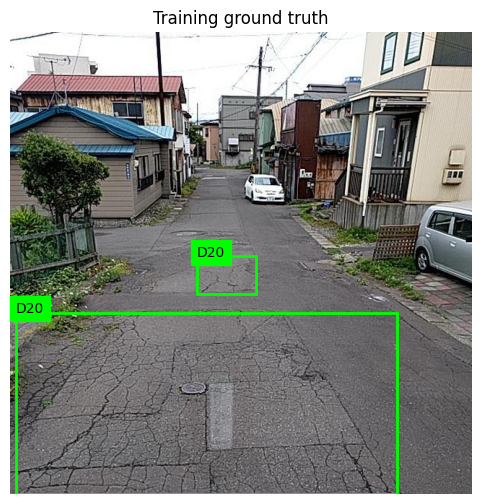

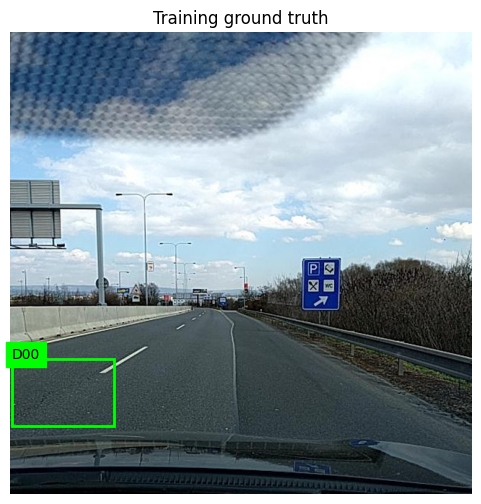

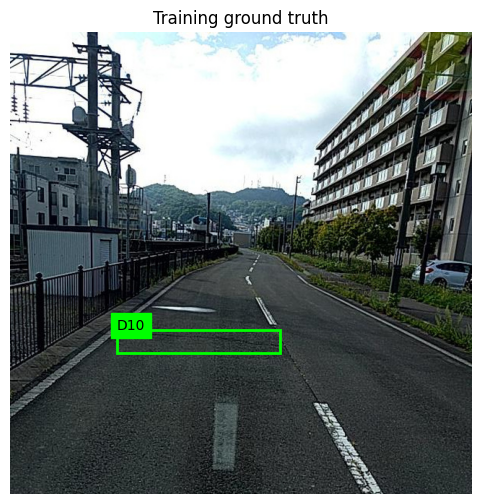

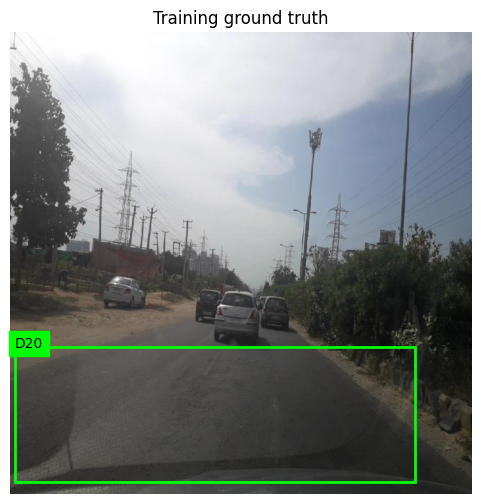

Saudi evaluation images: 77 Excluded: 1


In [14]:
def draw_boxes(ax,boxes,color,predicted=False):  #new
    for box in boxes:  #new
        if predicted:  #new
            x1,y1,x2,y2,confidence,c=box  #new
            text=f'{CODES[int(c)]} {confidence:.2f}'  #new
        else:
            c,x1,y1,x2,y2=box  #new
            text=CODES[int(c)]  #new
        ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color=color,linewidth=2))  #new
        ax.text(x1,y1,text,color='black',backgroundcolor=color)  #new

def ground_truth(path,split,width,height):  #new
    labels=read_yolo(label_path(path,split))  #new
    truth=labels.copy()  #new
    if len(labels):  #new
        truth[:,1]=(labels[:,1]-labels[:,3]/2)*width  #new
        truth[:,2]=(labels[:,2]-labels[:,4]/2)*height  #new
        truth[:,3]=(labels[:,1]+labels[:,3]/2)*width  #new
        truth[:,4]=(labels[:,2]+labels[:,4]/2)*height  #new
    return truth  #new

for path in random.Random(SEED).sample(list_images('train'),min(4,len(list_images('train')))):  #new
    with Image.open(path) as im:  #new
        image=np.asarray(im.convert('RGB'))  #new
    h,w=image.shape[:2]  #new
    fig,ax=plt.subplots(figsize=(6,6))  #new
    ax.imshow(image); ax.axis('off')  #new
    draw_boxes(ax,ground_truth(path,'train',w,h),'lime')  #new
    ax.set_title('Training ground truth')  #new
    plt.show(); plt.close(fig)  #new

EVAL_PATHS,excluded={},[]  #new
for split in SPLITS:  #new
    keep=[]  #new
    for path in list_images(split):  #new
        if split=='saudi_test' and EXCLUDE_EMPTY_SAUDI and len(read_yolo(label_path(path,split)))==0:  #new
            excluded.append(dict(split=split,image=str(path),reason='empty label; unconfirmed negative'))  #new
        else:
            keep.append(path)  #new
    assert keep,f'No usable images: {split}'  #new
    EVAL_PATHS[split]=keep  #new
    (SESSION/f'{split}_images.txt').write_text('\n'.join(str(p.resolve()) for p in keep)+'\n',encoding='utf-8')  #new
pd.DataFrame(excluded,columns=['split','image','reason']).to_csv(SESSION/'excluded_images.csv',index=False)  #new
RDD_YAML,SAUDI_YAML=SESSION/'rdd.yaml',SESSION/'saudi.yaml'  #new
dataset_config=dict(path=str(DATA_ROOT.resolve()),  #new
                    train=str((SESSION/'train_images.txt').resolve()),  #new
                    val=str((SESSION/'val_images.txt').resolve()),  #new
                    test=str((SESSION/'test_images.txt').resolve()),  #new
                    names=dict(enumerate(CLASS_NAMES)))  #new
RDD_YAML.write_text(yaml.safe_dump(dataset_config,sort_keys=False),encoding='utf-8')  #new
SAUDI_YAML.write_text(yaml.safe_dump({**dataset_config,'test':str((SESSION/'saudi_test_images.txt').resolve())},sort_keys=False),encoding='utf-8')  #new
print('Saudi evaluation images:',len(EVAL_PATHS['saudi_test']),'Excluded:',len(excluded))  #new


## 6. Train experiments and select on validation

The next cell, 6b, compares versions side by side.

Rank by validation mAP50-95, then mAP50 to break ties. Test results do not select experiments. Resume interrupted training from last.pt; completed checkpoints are reused. Changed training settings or dataset contents require a new session.

Augmentation ablation: yolo26s_640 uses the moderate recipe, yolo26s_640_noaug disables geometric/color transforms and optional Albumentations, and yolo26s_640_strong uses full mosaic, wider scale jitter, light mixup and erasing. All three use the same architecture, resolution, optimizer policy and epoch budget. See augmentation_comparison.csv for measured validation results after training.


In [15]:
from contextlib import contextmanager  #new
from unittest.mock import patch  #new
from ultralytics.data import augment as yolo_augment  #new
@contextmanager  #new
def augmentation_scope(recipe):  #new
    if recipe != 'none':  #new
        yield  #new
        return  #new
    class NoAlbumentations:  #new
        def __init__(self, *args, **kwargs):  #new
            pass  #new
        def __call__(self, labels):  #new
            return labels  #new
    # Disable optional color/blur transforms as well as geometric YOLO augmentations.  #new
    # This patch is scoped to one training call and restored even if training fails.  #new
    with patch.object(yolo_augment, 'Albumentations', NoAlbumentations):  #new
        yield  #new

if DEVICE=='cpu' and not ALLOW_CPU_TRAINING:  #new
    raise RuntimeError('Choose Colab Runtime > Change runtime type > GPU.')  #new
assert EXPERIMENTS and len({e['name'] for e in EXPERIMENTS})==len(EXPERIMENTS)  #new
frozen_config=dict(experiments=EXPERIMENTS,train_args=TRAIN_ARGS,aug_strong=AUG_STRONG,  #yolo26
                   dataset_fingerprint=DATASET_FINGERPRINT,class_names=CLASS_NAMES,no_aug=NO_AUG,  #new
                   ultralytics=ultralytics.__version__,nms_iou=NMS_IOU,max_det=MAX_DET)  #new
config_path=SESSION/'frozen_training_config.json'  #new
if config_path.exists():  #new
    assert json.loads(config_path.read_text(encoding='utf-8'))==frozen_config,'Data/settings changed: start a new session.'  #new
else:
    write_json(config_path,frozen_config)  #new
write_json(SESSION/'environment.json',dict(python=platform.python_version(),torch=torch.__version__,  #new
           ultralytics=ultralytics.__version__,cuda=torch.version.cuda,  #new
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'))  #new

def evaluate_ap(detector,data,split,folder,imgsz,augment=False):  #new
    folder=Path(folder)  #new
    folder.parent.mkdir(parents=True,exist_ok=True)  #new
    return detector.val(data=str(data),split=split,imgsz=imgsz,conf=0.001,  #new
                        iou=NMS_IOU,max_det=MAX_DET,batch=EVAL_BATCH,augment=augment,  #new
                        device=DEVICE,workers=WORKERS,plots=True,  #new
                        project=str(folder.parent),name=folder.name,exist_ok=True,verbose=False)  #new

experiment_rows=[]  #new
for experiment in EXPERIMENTS:  #new
    run_dir=SESSION/'training'/experiment['name']  #new
    completed=run_dir/'completed.json'  #new
    start=time.perf_counter()  #new
    if completed.exists():  #new
        row=json.loads(completed.read_text(encoding='utf-8'))  #new
        assert Path(row['best_weights']).is_file(),'Completed checkpoint missing.'  #new
        print('Reusing completed:',experiment['name'])  #new
    else:
        last=run_dir/'weights'/'last.pt'  #new
        best=run_dir/'weights'/'best.pt'  #new
        finished_training=False  #new
        if last.exists():  #new
            detector=YOLO(str(last))  #new
            checkpoint_epoch=int(detector.ckpt.get('epoch',-1))  #new
            # Final checkpoints have their optimizer stripped and epoch reset to -1.  #new
            # Also handle a disconnect after the final epoch but before stripping.  #new
            finished_training=checkpoint_epoch<0 or checkpoint_epoch>=EPOCHS-1  #new
            if not finished_training:  #new
                with augmentation_scope(experiment['augmentation']):  #new
                    detector.train(resume=True,device=DEVICE,workers=WORKERS)  #new
                best=Path(detector.trainer.best)  #new
        else:
            detector=YOLO(experiment['weights'])  #new
            run_args = dict(TRAIN_ARGS)  #new
            if experiment['augmentation']=='none':  #new
                run_args.update(NO_AUG)  #new
                run_args.update(auto_augment=None, erasing=0.0)  #new
            elif experiment['augmentation']=='strong':  #yolo26
                run_args.update(AUG_STRONG)  #yolo26
            with augmentation_scope(experiment['augmentation']):  #new
                detector.train(data=str(RDD_YAML),imgsz=experiment['imgsz'],  #new
                           device=DEVICE,workers=WORKERS,  #new
                           project=str(SESSION/'training'),name=experiment['name'],  #new
                           exist_ok=True,**run_args)  #new
            best=Path(detector.trainer.best)  #new
        assert best.is_file(),f'Missing checkpoint: {best}'  #new
        detector=YOLO(str(best))  #new
        validation=evaluate_ap(detector,RDD_YAML,'val',SESSION/'validation'/experiment['name'],experiment['imgsz'])  #new
        n_params=sum(p.numel() for p in detector.model.parameters())/1e6  #compare
        row=dict(**experiment,best_weights=str(best),params_M=round(n_params,2),weights_MB=round(best.stat().st_size/1e6,1),  #compare
                 val_mAP50=float(validation.box.map50),  #new
                 val_mAP50_95=float(validation.box.map),  #new
                 elapsed_min_this_execution=round((time.perf_counter()-start)/60,2))  #new
        write_json(completed,row)  #new
        del detector,validation  #new
        gc.collect()  #new
        if torch.cuda.is_available():
            torch.cuda.empty_cache()  #new
    experiment_rows.append(row)  #new
    pd.DataFrame(experiment_rows).to_csv(SESSION/'validation_experiments.csv',index=False)  #new
leaderboard=pd.DataFrame(experiment_rows).sort_values(['val_mAP50_95','val_mAP50'],ascending=False)  #new
display(leaderboard)  #new
winner=leaderboard.iloc[0].to_dict()  #new
BEST_W=Path(winner['best_weights'])  #new
IMGSZ=int(winner['imgsz'])  #new
model=YOLO(str(BEST_W))
print('Selected only on validation:',winner['name'])  #new

ablation = leaderboard[leaderboard['name'].isin(['yolo26s_640','yolo26s_640_noaug','yolo26s_640_strong'])]  #yolo26
ablation.to_csv(SESSION/'augmentation_comparison.csv', index=False)  #new
print('Augmentation comparison: same architecture, resolution and schedule; validation only.')  #new
display(ablation[['name','augmentation','val_mAP50','val_mAP50_95']])  #new


Reusing completed: yolo26n_640
Reusing completed: yolo26s_640
Reusing completed: yolo26m_640
Reusing completed: yolo26l_640
Reusing completed: yolo11s_640
Reusing completed: yolo11m_640
Reusing completed: yolov8s_640
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z/rdd.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, h

,name,weights,imgsz,augmentation,best_weights,params_M,weights_MB,val_mAP50,val_mAP50_95,elapsed_min_this_execution
0,yolo26n_640,yolo26n.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,2.54,5.5,0.372013,0.152017,5.86
1,yolo26s_640,yolo26s.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,9.95,20.3,0.357324,0.140631,6.96
10,yolo26s_640_noaug,yolo26s.pt,640,none,/content/drive/MyDrive/RoadScan_Min/Improved_R...,9.95,20.3,0.340308,0.133324,7.14
11,yolo26s_640_strong,yolo26s.pt,640,strong,/content/drive/MyDrive/RoadScan_Min/Improved_R...,9.95,20.3,0.348414,0.131855,7.30
4,yolo11s_640,yolo11s.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,9.43,19.2,0.326619,0.126395,6.25
6,yolov8s_640,yolov8s.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,11.14,22.5,0.328390,0.125573,6.88
8,yolo26s_960,yolo26s.pt,960,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,9.95,20.4,0.323236,0.121775,13.73
3,yolo26l_640,yolo26l.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,26.18,53.0,0.312775,0.116457,15.88
2,yolo26m_640,yolo26m.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,21.78,44.0,0.296157,0.104591,12.26
7,yolov8m_640,yolov8m.pt,640,moderate,/content/drive/MyDrive/RoadScan_Min/Improved_R...,25.86,52.0,0.267746,0.099061,9.93


Selected only on validation: yolo26n_640
Augmentation comparison: same architecture, resolution and schedule; validation only.


,name,augmentation,val_mAP50,val_mAP50_95
1,yolo26s_640,moderate,0.357324,0.140631
10,yolo26s_640_noaug,none,0.340308,0.133324
11,yolo26s_640_strong,strong,0.348414,0.131855


## 6b. Compare YOLO versions (validation only)

All models share the same data, epochs, seed, augmentation recipe and metric (RDD validation). The table and plots below show which **version** and **size** work best for road damage. Test sets are not used to choose.

Read with care: one seed per model and AutoBatch (batch size may differ per model) mean mAP gaps below about 0.5 points are within noise. Prefer a model that is clearly better, or similar but smaller/faster.

,name,family,size,imgsz,augmentation,params_M,weights_MB,val_mAP50,val_mAP50_95
0,yolo26n_640,yolo26,n,640,moderate,2.54,5.5,0.3720,0.1520
1,yolo26s_640,yolo26,s,640,moderate,9.95,20.3,0.3573,0.1406
2,yolo26s_640_noaug,yolo26,s,640,none,9.95,20.3,0.3403,0.1333
3,yolo26s_640_strong,yolo26,s,640,strong,9.95,20.3,0.3484,0.1319
4,yolo11s_640,yolo11,s,640,moderate,9.43,19.2,0.3266,0.1264
5,yolov8s_640,yolov8,s,640,moderate,11.14,22.5,0.3284,0.1256
6,yolo26s_960,yolo26,s,960,moderate,9.95,20.4,0.3232,0.1218
7,yolo26l_640,yolo26,l,640,moderate,26.18,53.0,0.3128,0.1165
8,yolo26m_640,yolo26,m,640,moderate,21.78,44.0,0.2962,0.1046
9,yolov8m_640,yolov8,m,640,moderate,25.86,52.0,0.2677,0.0991


size,l,m,n,s
family,,,,
yolo11,NaN,0.0634,NaN,0.1264
yolo26,0.1165,0.1046,0.152,0.1406
yolov8,NaN,0.0991,NaN,0.1256


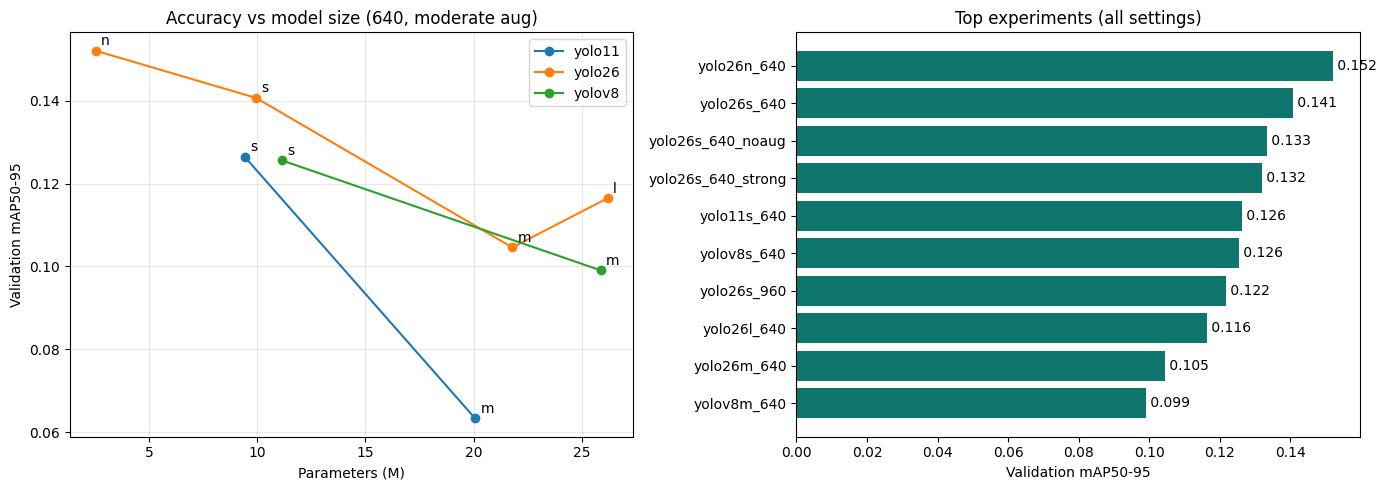

In [17]:
cmp_df=pd.DataFrame(experiment_rows).copy()  #compare
cmp_df['stem']=cmp_df['weights'].str.replace('.pt','',regex=False)  #compare
cmp_df['family']=cmp_df['stem'].str[:-1]   # yolo26 / yolo11 / yolov8  #compare
cmp_df['size']=cmp_df['stem'].str[-1]  #compare
for col in ['params_M','weights_MB']:  #compare
    if col not in cmp_df: cmp_df[col]=np.nan  #compare
cols=['name','family','size','imgsz','augmentation','params_M','weights_MB','val_mAP50','val_mAP50_95']  #compare
cmp_df=cmp_df[cols].sort_values('val_mAP50_95',ascending=False).reset_index(drop=True)  #compare
cmp_df.to_csv(SESSION/'version_comparison.csv',index=False)  #compare
display(cmp_df.round(4))  #compare

# Fair architecture comparison: same recipe (moderate) and same resolution (640).  #compare
fair=cmp_df[(cmp_df['augmentation']=='moderate')&(cmp_df['imgsz']==640)]  #compare
pivot=fair.pivot_table(index='family',columns='size',values='val_mAP50_95')  #compare
display(pivot.round(4))  #compare
fig,axes=plt.subplots(1,2,figsize=(14,5))  #compare
for fam,g in fair.groupby('family'):  #compare
    g=g.sort_values('params_M')  #compare
    axes[0].plot(g['params_M'],g['val_mAP50_95'],marker='o',label=fam)  #compare
    for _,r in g.iterrows():  #compare
        axes[0].annotate(r['size'],(r['params_M'],r['val_mAP50_95']),textcoords='offset points',xytext=(4,4))  #compare
axes[0].set(xlabel='Parameters (M)',ylabel='Validation mAP50-95',title='Accuracy vs model size (640, moderate aug)')  #compare
axes[0].legend(); axes[0].grid(alpha=.3)  #compare
top=cmp_df.head(10).iloc[::-1]  #compare
axes[1].barh(top['name'],top['val_mAP50_95'],color='#0f766e')  #compare
axes[1].set(xlabel='Validation mAP50-95',title='Top experiments (all settings)')  #compare
for i,v in enumerate(top['val_mAP50_95']): axes[1].text(v,i,f' {v:.3f}',va='center')  #compare
fig.tight_layout(); fig.savefig(SESSION/'version_comparison.png',dpi=150,bbox_inches='tight')  #compare
plt.show(); plt.close(fig)  #compare

## 7. Compare test-time augmentation on validation

TTA increases inference time. Enable it only if validation mAP50-95 improves by at least 0.2 percentage points. Keep the selected settings identical for evaluation and deployment.


In [18]:
tta_rows=[dict(augment=False,val_mAP50=float(winner['val_mAP50']),val_mAP50_95=float(winner['val_mAP50_95']))]  #new
USE_TTA=False  #new
if TRY_TTA:  #new
    try:  #yolo26
        tta_metrics=evaluate_ap(model,RDD_YAML,'val',SESSION/'validation'/'winner_tta',IMGSZ,augment=True)  #new
        tta_rows.append(dict(augment=True,val_mAP50=float(tta_metrics.box.map50),val_mAP50_95=float(tta_metrics.box.map)))  #new
        USE_TTA=float(tta_metrics.box.map)>=float(winner['val_mAP50_95'])+TTA_MIN_MAP_GAIN  #new
    except Exception as exc:  #yolo26
        # Some end-to-end checkpoints may not support TTA in every Ultralytics version.  #yolo26
        print('TTA skipped (not supported for this model/version):',repr(exc))  #yolo26
pd.DataFrame(tta_rows).to_csv(SESSION/'validation_tta.csv',index=False)  #new
display(pd.DataFrame(tta_rows))  #new
print('Frozen TTA:',USE_TTA)  #new

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2789.8±562.7 MB/s, size: 186.9 KB)
val: Scanning /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600/labels/val.cache... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 223.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 12.5it/s 16.0s
                   all        800       1440      0.485      0.381      0.375      0.153
Speed: 1.3ms preprocess, 13.5ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z/validation/winner_tta


,augment,val_mAP50,val_mAP50_95
0,False,0.372013,0.152017
1,True,0.375494,0.152990


Frozen TTA: False


## 8. Select confidence thresholds on validation

Operating-point Precision/Recall/F1 use confidence-ordered predictions matched to an unused ground-truth box of the same class at IoU >= 0.5. This explicit matching convention may differ slightly from Ultralytics. mAP comes from Ultralytics at conf=0.001, before operating-point threshold filtering.

Compare a common threshold with per-class thresholds on validation only. Classes with too few examples retain the common threshold; per-class thresholds require a minimum macro F-beta improvement. Beta=1 balances precision and recall.


,code,threshold,validation_instances
0,D00,0.15,360
1,D10,0.18,360
2,D20,0.21,360
3,D40,0.15,360


Common F-beta: 0.4176 Per-class F-beta: 0.4237 Use per-class: True


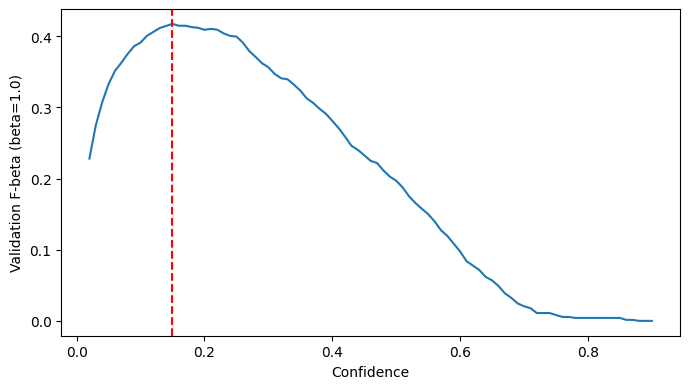

Model, resolution, TTA and thresholds FROZEN before test.


In [19]:
def box_iou_numpy(a,b):  #new
    a=np.asarray(a,dtype=float).reshape(-1,4)  #new
    b=np.asarray(b,dtype=float).reshape(-1,4)  #new
    lo=np.maximum(a[:,None,:2],b[None,:,:2])  #new
    hi=np.minimum(a[:,None,2:],b[None,:,2:])  #new
    intersection=np.maximum(hi-lo,0).prod(axis=2)  #new
    area_a=np.maximum(a[:,2:]-a[:,:2],0).prod(axis=1)  #new
    area_b=np.maximum(b[:,2:]-b[:,:2],0).prod(axis=1)  #new
    return intersection/np.maximum(area_a[:,None]+area_b[None,:]-intersection,1e-12)  #new

def match_flags(truth,predictions,iou_threshold=MATCH_IOU):  #new
    # truth=[class,x1,y1,x2,y2]; prediction=[x1,y1,x2,y2,confidence,class].  #new
    truth=np.asarray(truth,dtype=float).reshape(-1,5)  #new
    predictions=np.asarray(predictions,dtype=float).reshape(-1,6)  #new
    flags=np.zeros(len(predictions),dtype=bool)  #new
    overlaps=box_iou_numpy(predictions[:,:4],truth[:,1:])  #new
    used=set()  #new
    for p in np.argsort(-predictions[:,4],kind='stable'):  #new
        candidates=[g for g in range(len(truth)) if g not in used  #new
                    and int(truth[g,0])==int(predictions[p,5]) and overlaps[p,g]>=iou_threshold]  #new
        if candidates:  #new
            g=max(candidates,key=lambda g:overlaps[p,g])  #new
            used.add(g)  #new
            flags[p]=True  #new
    return flags  #new

def collect_predictions(detector,split):  #new
    paths=EVAL_PATHS[split]  #new
    collected=[]  #new
    for offset in range(0,len(paths),EVAL_BATCH):  #new
        batch=paths[offset:offset+EVAL_BATCH]  #new
        results=detector.predict([str(p) for p in batch],imgsz=IMGSZ,conf=0.001,  #new
                                 iou=NMS_IOU,max_det=MAX_DET,augment=USE_TTA,  #new
                                 device=DEVICE,batch=EVAL_BATCH,verbose=False)  #new
        assert len(results)==len(batch)  #new
        for path,result in zip(batch,results):  #new
            h,w=result.orig_shape  #new
            truth=ground_truth(path,split,w,h)  #new
            pred=result.boxes.data.cpu().numpy()[:,:6].astype(float)  #new
            collected.append(dict(image=str(path),truth=truth,pred=pred,tp=match_flags(truth,pred)))  #new
    return collected  #new

def aggregate_stats(records):  #new
    pred=np.concatenate([r['pred'] for r in records],axis=0)  #new
    tp=np.concatenate([r['tp'] for r in records])  #new
    support=sum((np.bincount(r['truth'][:,0].astype(int),minlength=NC) for r in records),np.zeros(NC,dtype=int))  #new
    return pred,tp,support  #new

def operating_metrics(stats,thresholds):  #new
    pred,tp,support=stats  #new
    thresholds=np.broadcast_to(np.asarray(thresholds,dtype=float),(NC,))  #new
    classes=pred[:,5].astype(int)  #new
    keep=pred[:,4]>=thresholds[classes]  #new
    counts=np.bincount(classes[keep],minlength=NC)  #new
    true_positive=np.bincount(classes[keep & tp],minlength=NC)  #new
    p=np.divide(true_positive,counts,out=np.zeros(NC,dtype=float),where=counts>0)  #new
    r=np.divide(true_positive,support,out=np.zeros(NC,dtype=float),where=support>0)  #new
    b2=THRESHOLD_BETA**2  #new
    fb=(1+b2)*p*r/np.maximum(b2*p+r,1e-12)  #new
    f1=2*p*r/np.maximum(p+r,1e-12)  #new
    return dict(P=p,R=r,F1=f1,Fbeta=fb,TP=true_positive,FP=counts-true_positive,  #new
                FN=support-true_positive,support=support)  #new

validation_records=collect_predictions(model,'val')  #new
validation_stats=aggregate_stats(validation_records)  #new
# Confidence-ordered class-aware matching is prefix-consistent; thresholds do not rematch lower scores.  #new
scores=np.asarray([operating_metrics(validation_stats,t)['Fbeta'] for t in THRESHOLD_GRID])  #new
common_idx=int(scores.mean(axis=1).argmax())  #new
COMMON_THRESHOLD=float(THRESHOLD_GRID[common_idx])  #new
class_thresholds=np.full(NC,COMMON_THRESHOLD)  #new
for c in range(NC):  #new
    if validation_stats[2][c]>=MIN_GT_FOR_CLASS_THRESHOLD:  #new
        class_thresholds[c]=THRESHOLD_GRID[int(scores[:,c].argmax())]  #new
common_score=float(scores[common_idx].mean())  #new
class_score=float(operating_metrics(validation_stats,class_thresholds)['Fbeta'].mean())  #new
use_class=TRY_PER_CLASS_THRESHOLDS and class_score>=common_score+MIN_PER_CLASS_GAIN  #new
THRESHOLDS=class_thresholds if use_class else np.full(NC,COMMON_THRESHOLD)  #new
display(pd.DataFrame(dict(code=CODES,threshold=THRESHOLDS,validation_instances=validation_stats[2])))  #new
print('Common F-beta:',round(common_score,4),'Per-class F-beta:',round(class_score,4),'Use per-class:',use_class)  #new
curve=pd.DataFrame({'threshold':THRESHOLD_GRID,'macro_Fbeta':scores.mean(axis=1)})  #new
curve.to_csv(SESSION/'validation_threshold_curve.csv',index=False)  #new
fig,ax=plt.subplots(figsize=(7,4))  #new
ax.plot(THRESHOLD_GRID,scores.mean(axis=1))  #new
ax.axvline(COMMON_THRESHOLD,ls='--',color='red')  #new
ax.set(xlabel='Confidence',ylabel=f'Validation F-beta (beta={THRESHOLD_BETA})')  #new
fig.tight_layout(); fig.savefig(SESSION/'validation_threshold_curve.png',dpi=150)  #new
plt.show(); plt.close(fig)  #new
deployment=dict(model=winner['name'],selected_on='RDD validation only',imgsz=IMGSZ,  #new
                nms_iou=NMS_IOU,max_det=MAX_DET,augment=USE_TTA,  #new
                class_names=CLASS_NAMES,codes=CODES,thresholds=THRESHOLDS.tolist(),  #new
                common_threshold=COMMON_THRESHOLD,per_class_thresholds=bool(use_class),  #new
                beta=THRESHOLD_BETA,match_iou=MATCH_IOU,  #new
                dataset_fingerprint=DATASET_FINGERPRINT,ultralytics=ultralytics.__version__)  #new
write_json(SESSION/'deployment_config.json',deployment)  #new
print('Model, resolution, TTA and thresholds FROZEN before test.')  #new


## 9. Final evaluation — clear decimal and percentage reports

RDD and Saudi tests are separate. Detection MACRO averages the four classes; it is not a fraction of successful images.

The final report includes **Image-level Accuracy (exact match)**: success requires correct presence/absence predictions for all four classes in an image. Values such as 0.92 and 92% are two formats for the same measured quantity, not a target or promised result. Accuracy is derived from predicted boxes above the frozen thresholds, but does not assess their locations. It is an additional metric, not a replacement for detection mAP.

Per-class image Accuracy and mean binary-label Accuracy are also saved; these can be inflated by absent classes. Always read them alongside exact-match Accuracy and detection Recall/mAP. Validation Accuracy is labeled separately from test Accuracy. No training-set Accuracy is claimed.

The confusion matrix uses spatial matching without a class restriction to expose class confusion. Detection Precision/Recall use the class-aware rule above and should not be reconstructed directly from this matrix. The Saudi test set is small.


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 72.8±14.5 MB/s, size: 171.3 KB)
val: Scanning /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600/labels/test... 800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 497.7it/s 1.6s
val: New cache created: /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 19.7it/s 10.1s
                   all        800       1440       0.47        0.4      0.366      0.139
Speed: 1.2ms preprocess, 4.7ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z/final_test/test/ap_curves


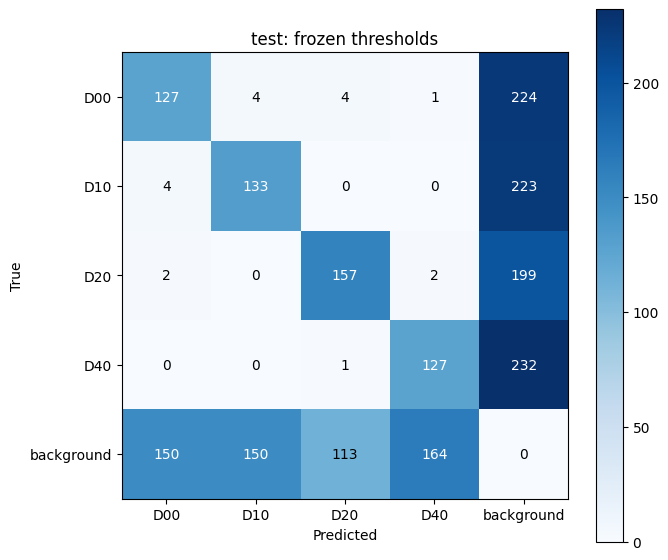

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 30.5±13.7 MB/s, size: 43.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600/labels/saudi_test... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 1.0Kit/s 0.1s
val: New cache created: /content/roadscan_improved_data/1aa095b5e20dd737/RoadScan_RDD_SaudiRD2_Train1600/labels/saudi_test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 10.8it/s 1.8s
                   all         77        128       0.28      0.179      0.111     0.0466
Speed: 3.9ms preprocess, 8.6ms inference, 0.0ms loss, 1.8ms 

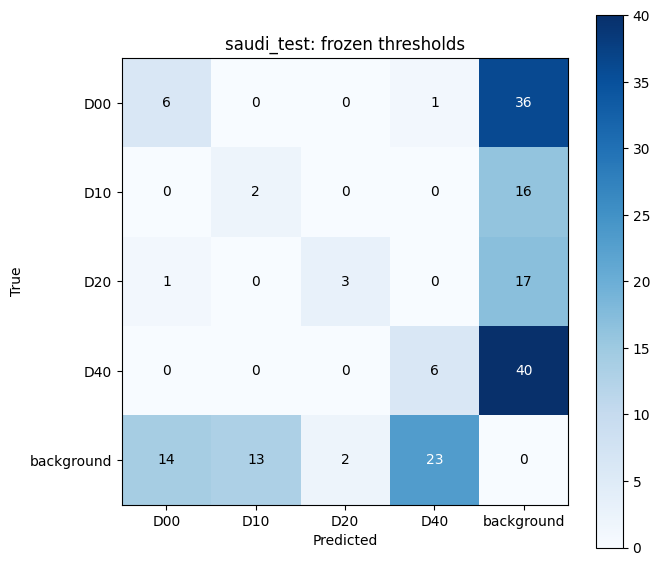

,split,code,images,instances,threshold,AP50,AP50_95,P,R,F1,TP,FP,FN
0,test,D00,800,360,0.15,0.309,0.118,0.452,0.356,0.398,128,155,232
1,test,D10,800,360,0.18,0.343,0.124,0.463,0.369,0.411,133,154,227
2,test,D20,800,360,0.21,0.491,0.203,0.571,0.436,0.494,157,118,203
3,test,D40,800,360,0.15,0.321,0.114,0.432,0.353,0.388,127,167,233
4,test,MACRO,800,1440,NaN,0.366,0.139,0.480,0.378,0.423,545,594,895
5,saudi_test,D00,77,43,0.15,0.045,0.014,0.286,0.140,0.187,6,15,37
6,saudi_test,D10,77,18,0.18,0.160,0.073,0.133,0.111,0.121,2,13,16
7,saudi_test,D20,77,21,0.21,0.159,0.076,0.600,0.143,0.231,3,2,18
8,saudi_test,D40,77,46,0.15,0.081,0.023,0.200,0.130,0.158,6,24,40
9,saudi_test,MACRO,77,128,NaN,0.111,0.047,0.305,0.131,0.174,17,54,111



IMAGE-LEVEL ACCURACY: all four damage-presence labels must match.
This success measure ignores bounding-box location; read detection mAP below as well.
validation: 417/800 successful images | Accuracy = 0.5212 (52.12%)
test: 422/800 successful images | Accuracy = 0.5275 (52.75%)
saudi_test: 14/77 successful images | Accuracy = 0.1818 (18.18%)
Validation Accuracy is measured on data used for tuning; test Accuracy is separate.

FINAL TEST PERFORMANCE — decimals and percentages describe the same measured values


,split,metric,decimal,percentage
0,test,Image-level Accuracy (exact match),0.5275,52.75%
1,test,Detection mAP@0.5,0.3660,36.60%
2,test,Detection mAP@0.5:0.95,0.1394,13.94%
3,test,Detection Precision (macro),0.4796,47.96%
4,test,Detection Recall (macro),0.3785,37.85%
5,test,Detection F1 (macro),0.4230,42.30%
6,saudi_test,Image-level Accuracy (exact match),0.1818,18.18%
7,saudi_test,Detection mAP@0.5,0.1112,11.12%
8,saudi_test,Detection mAP@0.5:0.95,0.0466,4.66%
9,saudi_test,Detection Precision (macro),0.3048,30.48%


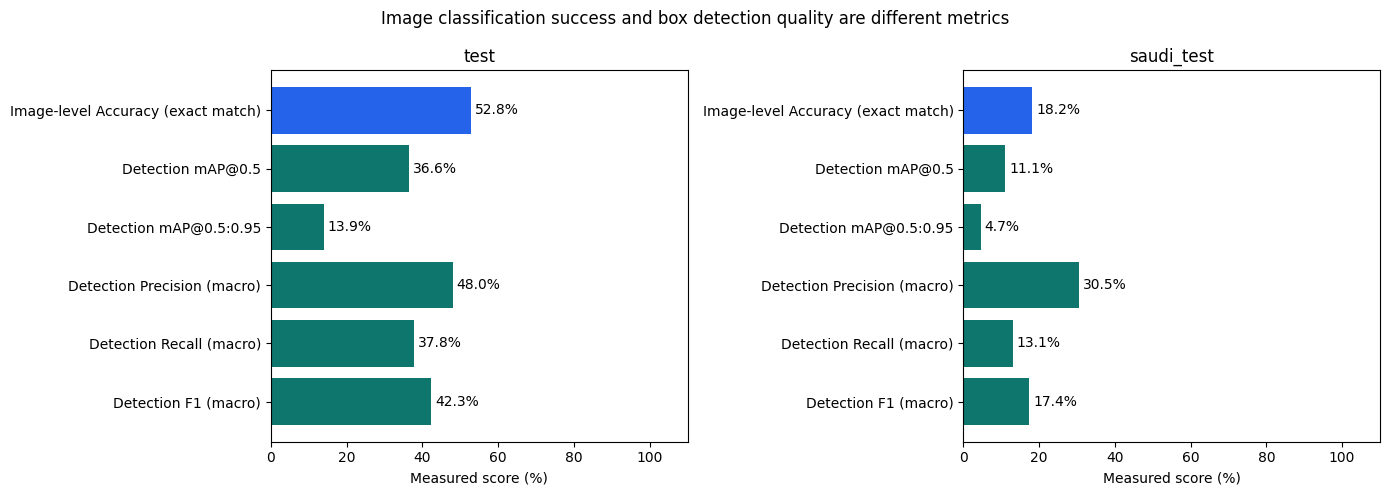

In [20]:
def confusion_matrix_spatial(records,thresholds):  #new
    matrix=np.zeros((NC+1,NC+1),dtype=int)  # Rows=true, columns=predicted; last=background.  #new
    for rec in records:  #new
        truth,pred=rec['truth'],rec['pred']  #new
        pred=pred[pred[:,4]>=thresholds[pred[:,5].astype(int)]]  #new
        overlaps=box_iou_numpy(pred[:,:4],truth[:,1:])  #new
        used_pred,used_gt=set(),set()  #new
        pairs=np.argwhere(overlaps>=MATCH_IOU)  #new
        ordered=sorted(pairs.tolist(),key=lambda ij:overlaps[ij[0],ij[1]],reverse=True)  #new
        for p,g in ordered:  #new
            if p not in used_pred and g not in used_gt:  #new
                matrix[int(truth[g,0]),int(pred[p,5])]+=1  #new
                used_pred.add(p); used_gt.add(g)  #new
        for g in set(range(len(truth)))-used_gt:  #new
            matrix[int(truth[g,0]),NC]+=1  #new
        for p in set(range(len(pred)))-used_pred:  #new
            matrix[NC,int(pred[p,5])]+=1  #new
    return matrix  #new

all_tables,TEST_RECORDS=[],{}  #new
for split in ['test','saudi_test']:  #new
    folder=SESSION/'final_test'/split  #new
    folder.mkdir(parents=True,exist_ok=True)  #new
    ap_metrics=evaluate_ap(model,RDD_YAML if split=='test' else SAUDI_YAML,'test',folder/'ap_curves',IMGSZ,USE_TTA)  #new
    recs=collect_predictions(model,split)  #new
    TEST_RECORDS[split]=recs  #new
    point=operating_metrics(aggregate_stats(recs),THRESHOLDS)  #new
    ap_by_class={int(c):(float(ap_metrics.box.ap50[i]),float(ap_metrics.box.ap[i]))  #new
                 for i,c in enumerate(ap_metrics.box.ap_class_index)}  #new
    rows=[]
    for c in range(NC):  #new
        ap50,ap95=ap_by_class.get(c,(0.0,0.0))  #new
        rows.append(dict(split=split,code=CODES[c],images=len(recs),instances=int(point['support'][c]),  #new
                         threshold=float(THRESHOLDS[c]),AP50=ap50,AP50_95=ap95,  #new
                         **{k:float(point[k][c]) for k in ['P','R','F1']},  #new
                         **{k:int(point[k][c]) for k in ['TP','FP','FN']}))  #new
    rows.append(dict(split=split,code='MACRO',images=len(recs),instances=int(point['support'].sum()),  #new
                     threshold=None,AP50=float(ap_metrics.box.map50),AP50_95=float(ap_metrics.box.map),  #new
                     **{k:float(point[k].mean()) for k in ['P','R','F1']},  #new
                     **{k:int(point[k].sum()) for k in ['TP','FP','FN']}))  #new
    table=pd.DataFrame(rows)  #new
    all_tables.append(table)  #new
    table.to_csv(folder/'metrics.csv',index=False)  #new
    errors,serializable=[],[]  #new
    for rec in recs:  #new
        pred=rec['pred']  #new
        keep=pred[:,4]>=THRESHOLDS[pred[:,5].astype(int)]  #new
        tp=int(rec['tp'][keep].sum())  #new
        errors.append(dict(image=rec['image'],ground_truth_boxes=len(rec['truth']),  #new
                           detections=int(keep.sum()),TP=tp,FP=int(keep.sum())-tp,FN=len(rec['truth'])-tp))  #new
        serializable.append(dict(image=rec['image'],truth=rec['truth'].tolist(),pred=pred[keep].tolist()))  #new
    pd.DataFrame(errors).sort_values(['FN','FP'],ascending=False).to_csv(folder/'image_errors.csv',index=False)  #new
    write_json(folder/'predictions_at_frozen_thresholds.json',serializable)  #new
    matrix=confusion_matrix_spatial(recs,THRESHOLDS)  #new
    labels=CODES+['background']  #new
    pd.DataFrame(matrix,index=labels,columns=labels).to_csv(folder/'confusion_matrix.csv')  #new
    fig,ax=plt.subplots(figsize=(7,6))  #new
    heat=ax.imshow(matrix,cmap='Blues')  #new
    for (y,x),v in np.ndenumerate(matrix):  #new
        ax.text(x,y,str(v),ha='center',va='center',color='white' if v>matrix.max()/2 else 'black')  #new
    ax.set(xticks=range(NC+1),yticks=range(NC+1),xticklabels=labels,yticklabels=labels,  #new
           xlabel='Predicted',ylabel='True',title=f'{split}: frozen thresholds')  #new
    fig.colorbar(heat,ax=ax); fig.tight_layout(); fig.savefig(folder/'confusion_matrix.png',dpi=150)  #new
    plt.show(); plt.close(fig)  #new
detector_results=pd.concat(all_tables,ignore_index=True)  #new
detector_results.to_csv(SESSION/'detector_results.csv',index=False)  #new
display(detector_results.round(3))


def image_accuracy_report(records, split, thresholds):  #new
    actual = np.zeros((len(records), NC), dtype=int)  #new
    predicted = np.zeros_like(actual)  #new
    image_rows = []  #new
    for i, rec in enumerate(records):  #new
        actual[i, rec['truth'][:, 0].astype(int)] = 1  #new
        detections = rec['pred']  #new
        keep = detections[:, 4] >= thresholds[detections[:, 5].astype(int)]  #new
        predicted[i, detections[keep, 5].astype(int)] = 1  #new
        success = bool(np.array_equal(actual[i], predicted[i]))  #new
        image_rows.append(dict(  #new
            split=split, image=rec['image'], success=int(success),  #new
            true_classes=','.join(CODES[c] for c in np.flatnonzero(actual[i])),  #new
            predicted_classes=','.join(CODES[c] for c in np.flatnonzero(predicted[i])),  #new
            **{f'true_{CODES[c]}': int(actual[i,c]) for c in range(NC)},  #new
            **{f'pred_{CODES[c]}': int(predicted[i,c]) for c in range(NC)}  #new
        ))  #new
    assert len(records) > 0, 'Accuracy is undefined for an empty dataset.'  #new
    successes = int(np.all(actual == predicted, axis=1).sum())  #new
    exact_accuracy = successes / len(records)  #new
    binary_accuracy = float((actual == predicted).mean())  #new
    summary = dict(  #new
        split=split, successful_images=successes, total_images=len(records),  #new
        image_exact_match_accuracy=exact_accuracy,  #new
        image_exact_match_accuracy_percent=100 * exact_accuracy,  #new
        mean_binary_label_accuracy=binary_accuracy,  #new
        mean_binary_label_accuracy_percent=100 * binary_accuracy  #new
    )  #new
    class_rows = []  #new
    for c in range(NC):  #new
        tp = int(((actual[:,c] == 1) & (predicted[:,c] == 1)).sum())  #new
        tn = int(((actual[:,c] == 0) & (predicted[:,c] == 0)).sum())  #new
        fp = int(((actual[:,c] == 0) & (predicted[:,c] == 1)).sum())  #new
        fn = int(((actual[:,c] == 1) & (predicted[:,c] == 0)).sum())  #new
        accuracy = (tp + tn) / len(records)  #new
        class_rows.append(dict(split=split, code=CODES[c], total_images=len(records),  #new
                               image_TP=tp, image_TN=tn, image_FP=fp, image_FN=fn,  #new
                               image_binary_accuracy=accuracy,  #new
                               image_binary_accuracy_percent=100*accuracy))  #new
    return summary, pd.DataFrame(class_rows), pd.DataFrame(image_rows)  #new

accuracy_summaries, accuracy_classes, image_predictions = [], [], []  #new
accuracy_sets = {'validation': validation_records, **TEST_RECORDS}  #new
for split, records in accuracy_sets.items():  #new
    summary, per_class, images = image_accuracy_report(records, split, THRESHOLDS)  #new
    accuracy_summaries.append(summary)  #new
    accuracy_classes.append(per_class)  #new
    image_predictions.append(images)  #new
accuracy_summary = pd.DataFrame(accuracy_summaries)  #new
accuracy_summary.to_csv(SESSION/'accuracy_summary.csv', index=False)  #new
pd.concat(accuracy_classes, ignore_index=True).to_csv(SESSION/'accuracy_per_class.csv', index=False)  #new
pd.concat(image_predictions, ignore_index=True).to_csv(SESSION/'image_level_predictions.csv', index=False)  #new

print('\nIMAGE-LEVEL ACCURACY: all four damage-presence labels must match.')  #new
print('This success measure ignores bounding-box location; read detection mAP below as well.')  #new
for row in accuracy_summaries:  #new
    print(f"{row['split']}: {row['successful_images']}/{row['total_images']} successful images | "  #new
          f"Accuracy = {row['image_exact_match_accuracy']:.4f} "  #new
          f"({row['image_exact_match_accuracy_percent']:.2f}%)")  #new
print('Validation Accuracy is measured on data used for tuning; test Accuracy is separate.')  #new

performance_rows = []  #new
for split in TEST_RECORDS:  #new
    detection = detector_results[(detector_results['split']==split) & (detector_results['code']=='MACRO')].iloc[0]  #new
    acc = accuracy_summary[accuracy_summary['split']==split].iloc[0]  #new
    definitions = [  #new
        ('Image-level Accuracy (exact match)', float(acc['image_exact_match_accuracy'])),  #new
        ('Detection mAP@0.5', float(detection['AP50'])),  #new
        ('Detection mAP@0.5:0.95', float(detection['AP50_95'])),  #new
        ('Detection Precision (macro)', float(detection['P'])),  #new
        ('Detection Recall (macro)', float(detection['R'])),  #new
        ('Detection F1 (macro)', float(detection['F1']))  #new
    ]  #new
    for metric, value in definitions:  #new
        performance_rows.append(dict(split=split, metric=metric, decimal=value, percentage=100*value))  #new
performance_summary = pd.DataFrame(performance_rows)  #new
performance_summary.to_csv(SESSION/'performance_summary.csv', index=False)  #new
clear_table = performance_summary.copy()  #new
clear_table['decimal'] = clear_table['decimal'].map(lambda value: f'{value:.4f}')  #new
clear_table['percentage'] = clear_table['percentage'].map(lambda value: f'{value:.2f}%')  #new
print('\nFINAL TEST PERFORMANCE — decimals and percentages describe the same measured values')  #new
display(clear_table)  #new
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)  #new
for ax, split in zip(axes, TEST_RECORDS):  #new
    frame = performance_summary[performance_summary['split']==split]  #new
    colors = ['#2563eb'] + ['#0f766e']*(len(frame)-1)  #new
    ax.barh(frame['metric'], frame['percentage'], color=colors)  #new
    ax.invert_yaxis()  #new
    ax.set_xlim(0, 110)  #new
    ax.set(title=split, xlabel='Measured score (%)')  #new
    for i, value in enumerate(frame['percentage']):  #new
        ax.text(value+1, i, f'{value:.1f}%', va='center')  #new
fig.suptitle('Image classification success and box detection quality are different metrics')  #new
fig.tight_layout()  #new
fig.savefig(SESSION/'performance_summary.png', dpi=160, bbox_inches='tight')  #new
plt.show()  #new
plt.close(fig)  #new


## 10. Compare ground truth and predictions

Show eight fixed random Saudi images, then four images with the most missed damage boxes. Selected failures are diagnostic examples, not an additional representative sample or a basis for tuning on test data.


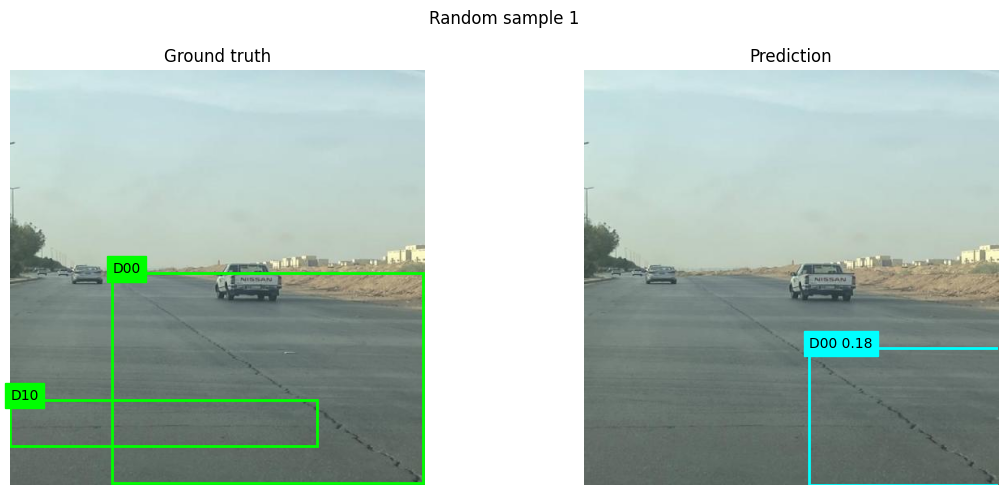

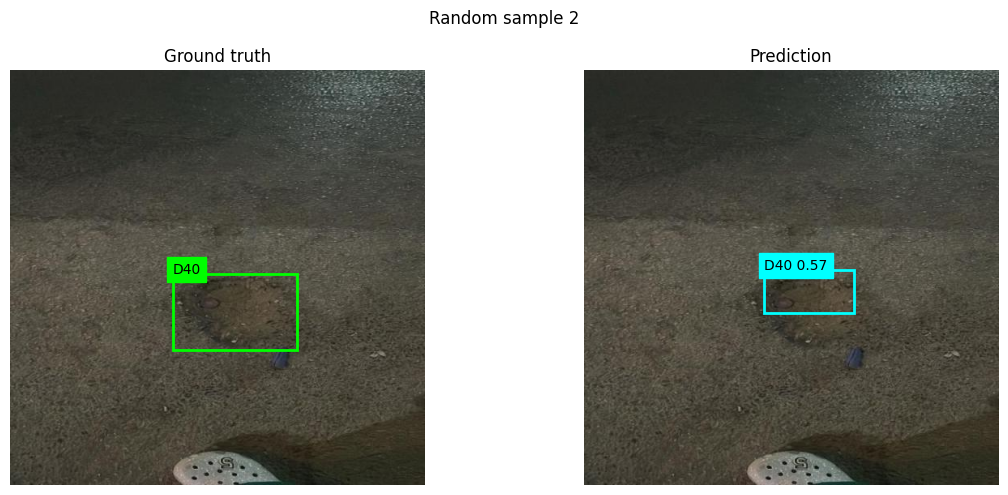

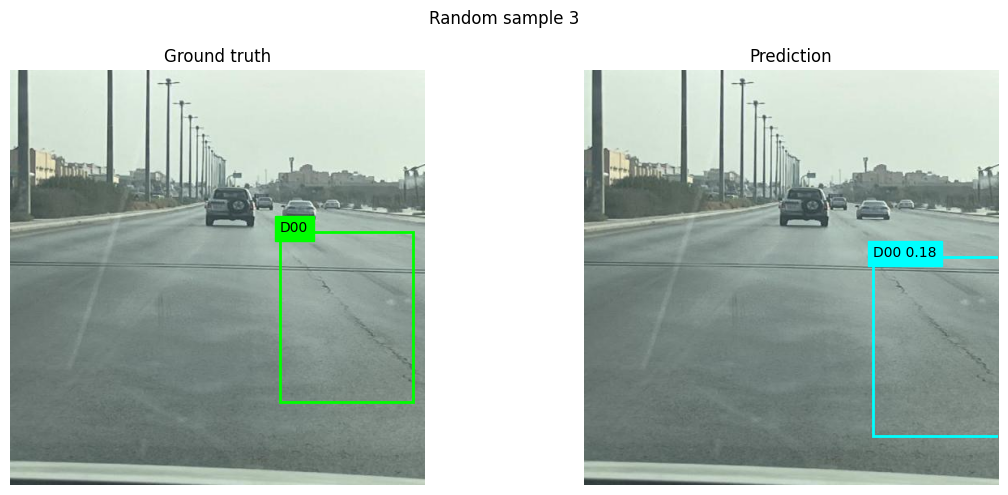

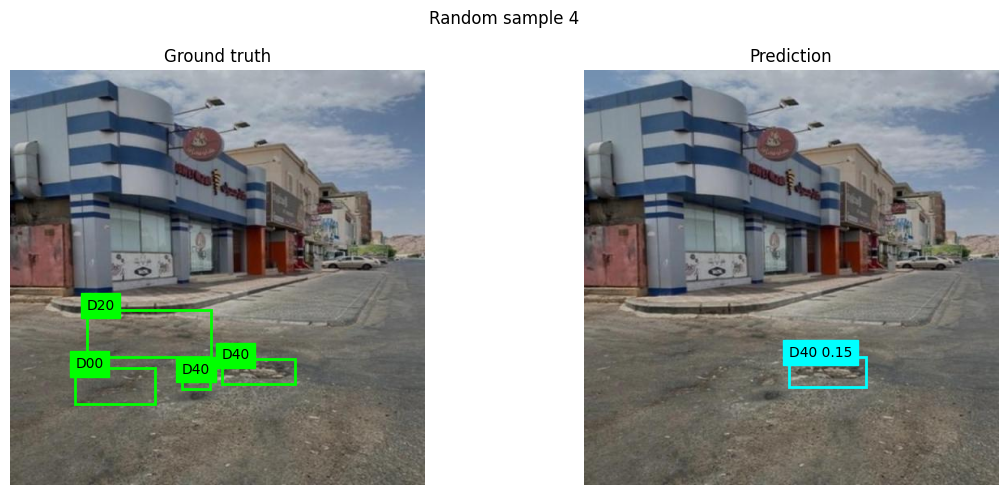

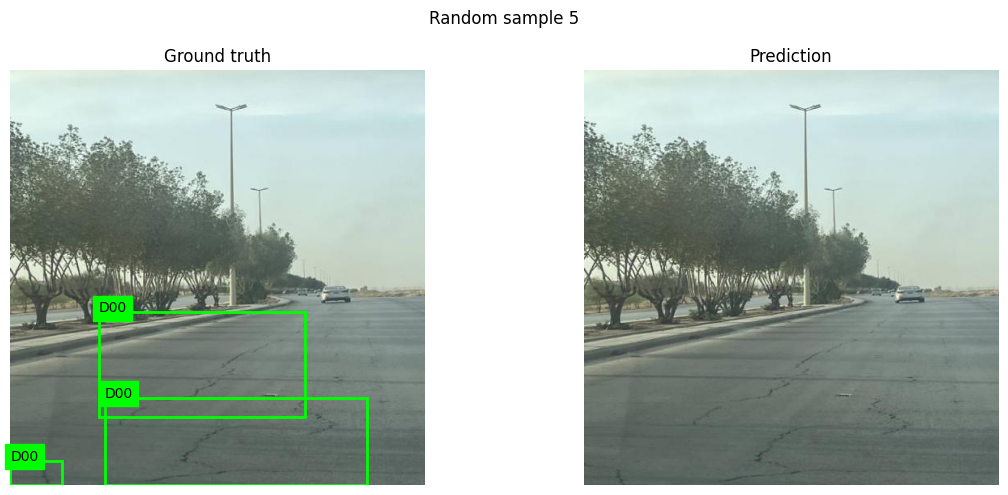

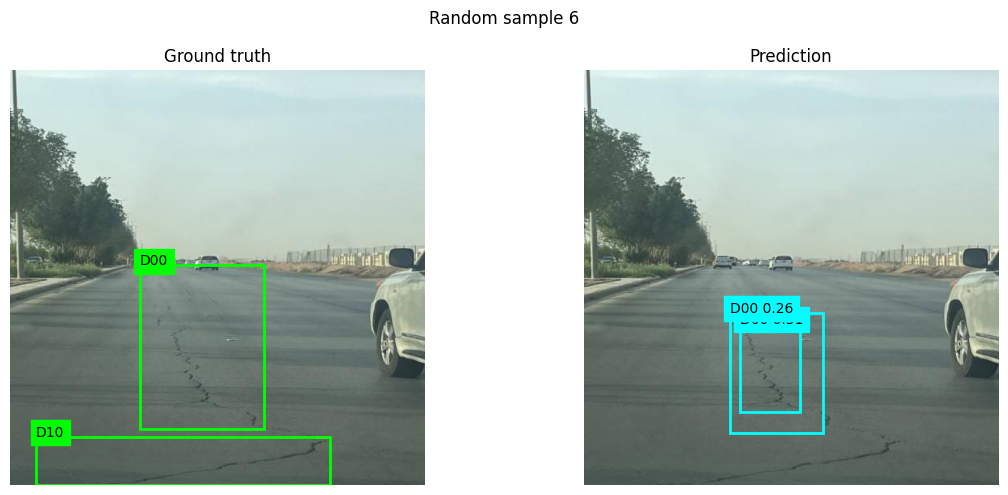

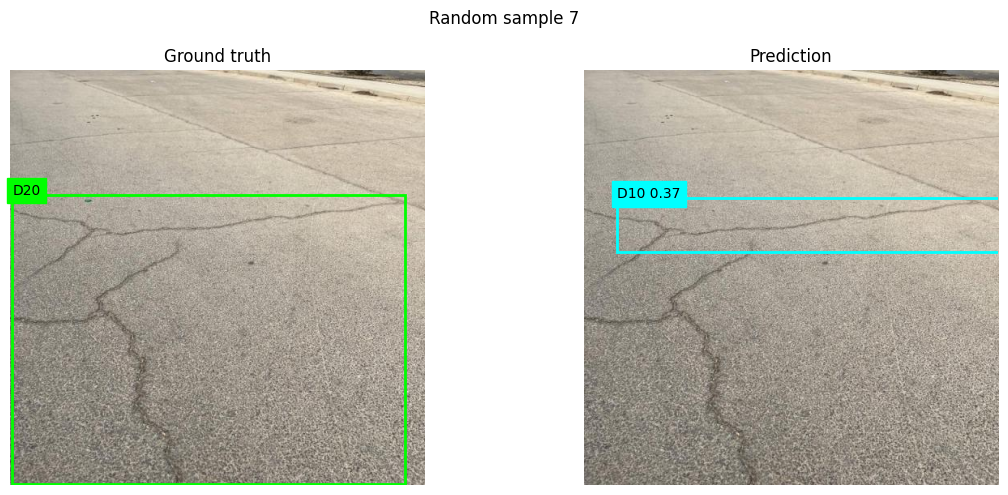

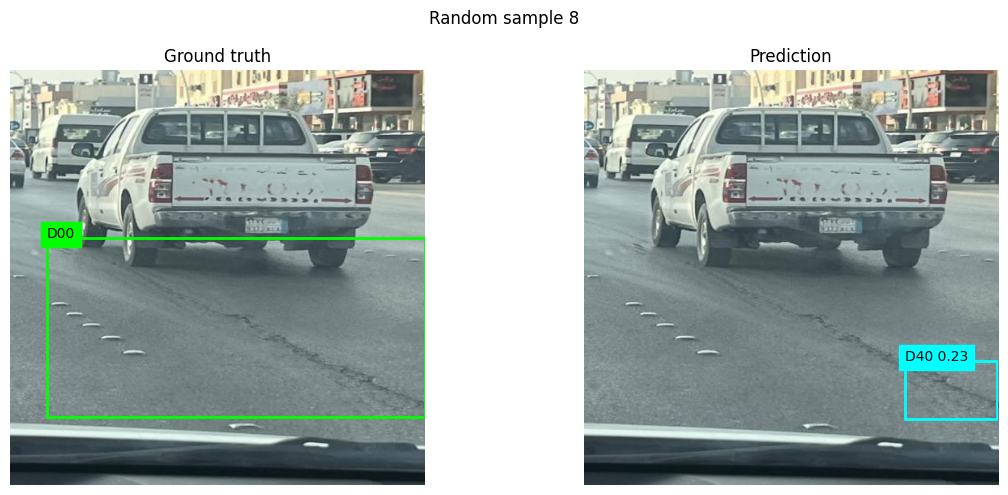

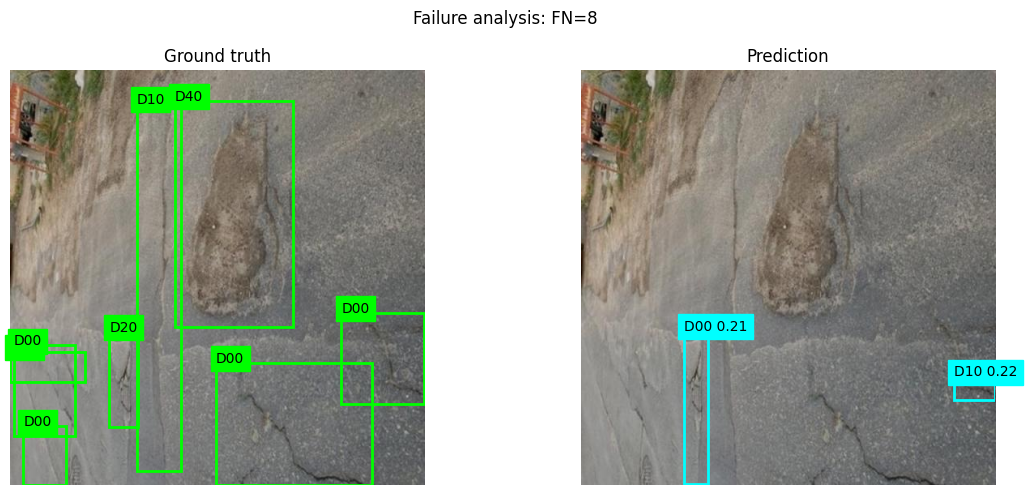

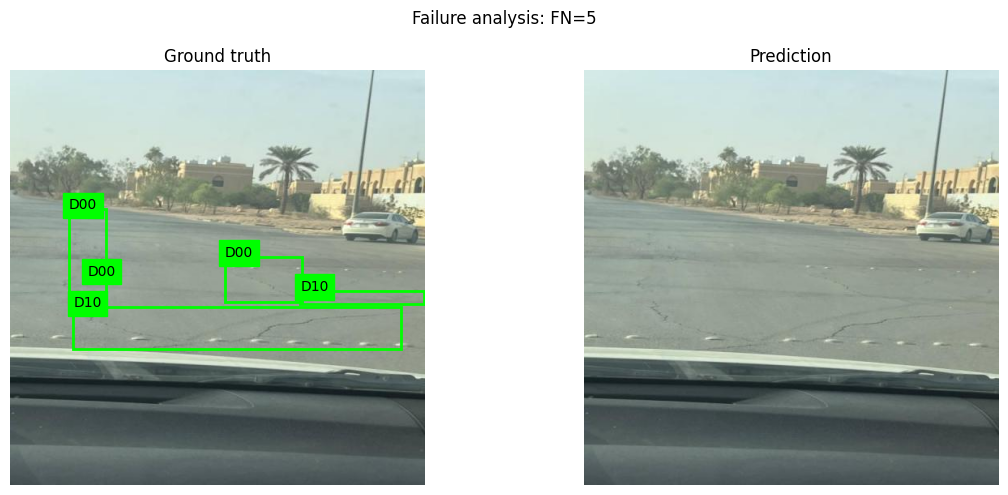

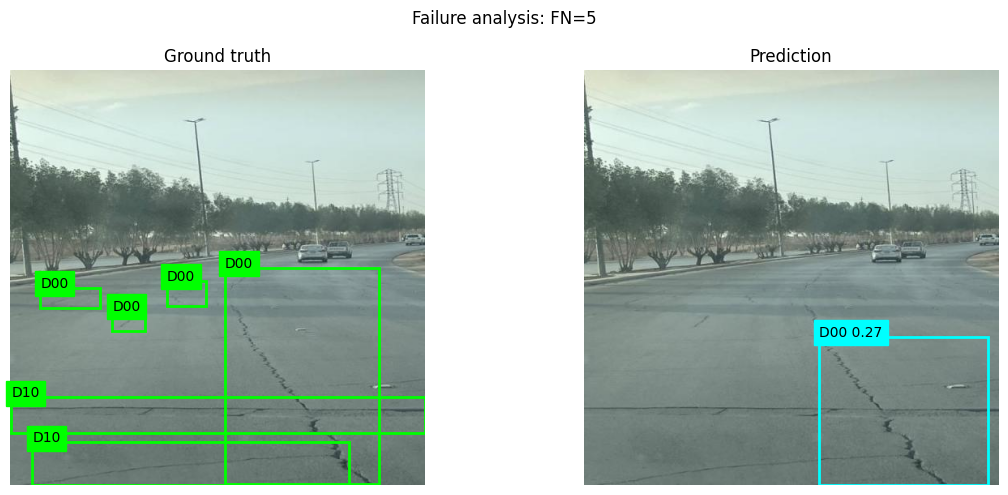

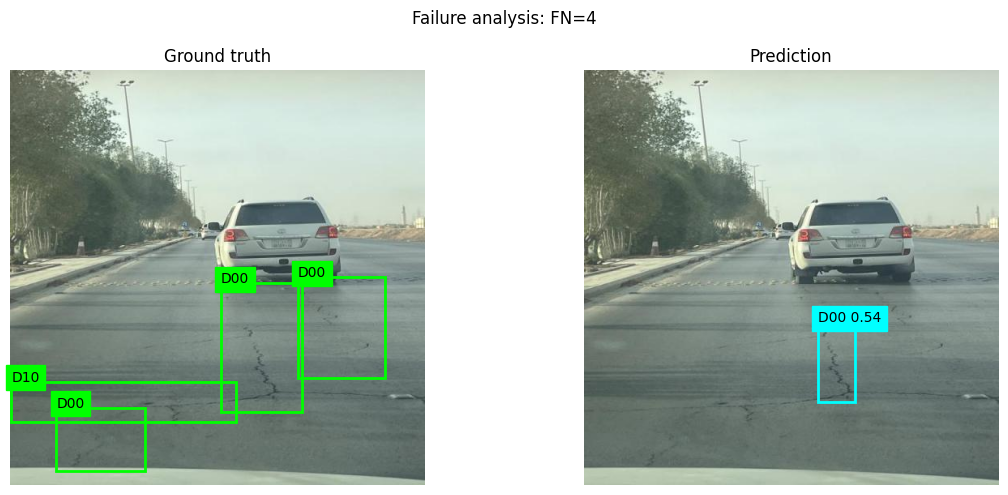

In [21]:
def show_comparison(rec,title,save_file):  #new
    with Image.open(rec['image']) as im:  #new
        image=np.asarray(im.convert('RGB'))  #new
    fig,axes=plt.subplots(1,2,figsize=(12,5))  #new
    for ax in axes:  #new
        ax.imshow(image); ax.axis('off')  #new
    draw_boxes(axes[0],rec['truth'],'lime')  #new
    pred=rec['pred']  #new
    keep=pred[:,4]>=THRESHOLDS[pred[:,5].astype(int)]  #new
    draw_boxes(axes[1],pred[keep],'cyan',predicted=True)  #new
    axes[0].set_title('Ground truth'); axes[1].set_title('Prediction')  #new
    fig.suptitle(title); fig.tight_layout(); fig.savefig(save_file,dpi=140)  #new
    plt.show(); plt.close(fig)  #new

visual_dir=SESSION/'visual_review'  #new
visual_dir.mkdir(exist_ok=True)  #new
saudi_records=TEST_RECORDS['saudi_test']  #new
for i,rec in enumerate(random.Random(SEED).sample(saudi_records,min(8,len(saudi_records)))):  #new
    show_comparison(rec,f'Random sample {i+1}',visual_dir/f'random_{i+1:02d}.png')  #new
def missed_boxes(rec):  #new
    pred=rec['pred']  #new
    keep=pred[:,4]>=THRESHOLDS[pred[:,5].astype(int)]  #new
    return len(rec['truth'])-int(rec['tp'][keep].sum())  #new
for i,rec in enumerate(sorted(saudi_records,key=missed_boxes,reverse=True)[:4]):  #new
    show_comparison(rec,f'Failure analysis: FN={missed_boxes(rec)}',visual_dir/f'failure_{i+1:02d}.png')  #new


## 11. Train a ResNet18 baseline and compare image-level performance

Compare damage-presence F1 only on shared images after verifying identical ground truth. Do not tune baseline thresholds on test data. This comparison does not measure bounding-box localization.

RUN_BASELINE=True trains a separate ImageNet-pretrained ResNet18 with four sigmoid outputs. The full image is resized to avoid dropping labeled damage through cropping. BCE loss uses class weights from training only; checkpoint and thresholds use validation only. It saves its own test predictions, Accuracy comparison and F1 comparison with YOLO. This is an image-level reference, not a competing box detector.

The baseline may retrain when this cell is rerun. Its best checkpoint is saved to Drive each time validation improves. Set RUN_BASELINE=False only when intentionally reusing existing baseline prediction files.


In [22]:

if RUN_BASELINE:  #new
    import torchvision  #new
    from torchvision import transforms  #new
    from torchvision.models import resnet18, ResNet18_Weights  #new
    from torch.utils.data import Dataset, DataLoader  #new
    from sklearn.metrics import average_precision_score  #new
    BASELINE_DIR.mkdir(parents=True, exist_ok=True)  #new
    baseline_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')  #new
    # Preserve the entire road scene. A center/random crop could remove a labeled  #new
    # damage while retaining its positive image-level label.  #new
    normalize = transforms.Normalize([.485,.456,.406],[.229,.224,.225])  #new
    baseline_train_transform = transforms.Compose([  #new
        transforms.Resize((224,224)), transforms.RandomHorizontalFlip(.5),  #new
        transforms.ColorJitter(brightness=.15,contrast=.15,saturation=.1),  #new
        transforms.ToTensor(), normalize])  #new
    baseline_eval_transform = transforms.Compose([  #new
        transforms.Resize((224,224)), transforms.ToTensor(), normalize])  #new

    class RoadPresenceDataset(Dataset):  #new
        def __init__(self, split, transform):  #new
            self.split, self.transform = split, transform  #new
            self.paths = EVAL_PATHS[split]  #new
            self.targets = []  #new
            for path in self.paths:  #new
                target = np.zeros(NC, dtype=np.float32)  #new
                target[read_yolo(label_path(path,split))[:,0].astype(int)] = 1  #new
                self.targets.append(target)  #new
        def __len__(self):  #new
            return len(self.paths)  #new
        def __getitem__(self, index):  #new
            with Image.open(self.paths[index]) as image:  #new
                tensor = self.transform(image.convert('RGB'))  #new
            return tensor, torch.from_numpy(self.targets[index]), self.paths[index].name  #new

    def baseline_loader(split, training=False):  #new
        dataset = RoadPresenceDataset(split, baseline_train_transform if training else baseline_eval_transform)  #new
        generator = torch.Generator().manual_seed(SEED)  #new
        return DataLoader(dataset, batch_size=BASELINE_BATCH, shuffle=training,  #new
                          num_workers=WORKERS, pin_memory=baseline_device.type=='cuda', generator=generator)  #new

    def baseline_predict(classifier, loader):  #new
        classifier.eval()  #new
        actual, probabilities, names = [], [], []  #new
        with torch.inference_mode():  #new
            for images, targets, filenames in loader:  #new
                probability = classifier(images.to(baseline_device)).sigmoid().cpu().numpy()  #new
                probabilities.append(probability)  #new
                actual.append(targets.numpy())  #new
                names.extend(filenames)  #new
        return np.concatenate(actual), np.concatenate(probabilities), names  #new

    classifier = resnet18(weights=ResNet18_Weights.DEFAULT)  #new
    classifier.fc = torch.nn.Linear(classifier.fc.in_features, NC)  #new
    classifier.to(baseline_device)  #new
    optimizer = torch.optim.AdamW(classifier.parameters(),lr=BASELINE_LEARNING_RATE,weight_decay=1e-4)  #new
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=BASELINE_EPOCHS)  #new
    train_loader, val_loader = baseline_loader('train',True), baseline_loader('val')  #new
    # Positive weighting is calculated on TRAIN only.  #new
    train_targets = np.asarray(train_loader.dataset.targets)  #new
    positive = train_targets.sum(axis=0)  #new
    pos_weight = torch.tensor((len(train_targets)-positive)/np.maximum(positive,1),dtype=torch.float32,device=baseline_device)  #new
    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)  #new
    best_score, stale, history = -1.0, 0, []  #new
    baseline_best = BASELINE_DIR/'resnet18_best.pt'  #new
    for epoch in range(BASELINE_EPOCHS):  #new
        classifier.train()  #new
        total_loss, seen = 0.0, 0  #new
        for images, targets, _ in train_loader:  #new
            images, targets = images.to(baseline_device), targets.to(baseline_device)  #new
            optimizer.zero_grad(set_to_none=True)  #new
            loss = criterion(classifier(images),targets)  #new
            loss.backward()  #new
            optimizer.step()  #new
            total_loss += float(loss.detach()) * len(images)  #new
            seen += len(images)  #new
        scheduler.step()  #new
        actual, probabilities, _ = baseline_predict(classifier,val_loader)  #new
        # Exclude undefined classes from checkpoint selection, never infer from tests.  #new
        valid = [c for c in range(NC) if len(np.unique(actual[:,c]))==2]  #new
        assert valid, 'Baseline validation must contain both labels for at least one class.'  #new
        score = float(np.mean([average_precision_score(actual[:,c],probabilities[:,c]) for c in valid]))  #new
        history.append(dict(epoch=epoch+1,train_loss=total_loss/seen,val_macro_image_AP=score))  #new
        print(f'Baseline epoch {epoch+1}/{BASELINE_EPOCHS}: loss={total_loss/seen:.4f}, validation image AP={score:.4f}')  #new
        if score > best_score:  #new
            best_score, stale = score, 0  #new
            torch.save(classifier.state_dict(),baseline_best)  #new
        else:
            stale += 1  #new
        pd.DataFrame(history).to_csv(BASELINE_DIR/'training_history.csv',index=False)  #new
        if stale >= BASELINE_PATIENCE:  #new
            print('Baseline early stopping.')  #new
            break  #new
    classifier.load_state_dict(torch.load(baseline_best,map_location=baseline_device,weights_only=True))  #new
    actual, probabilities, _ = baseline_predict(classifier,val_loader)  #new
    baseline_thresholds = np.full(NC,.5)  #new
    for c in range(NC):  #new
        scores_for_class = []  #new
        for threshold in THRESHOLD_GRID:  #new
            guessed = probabilities[:,c] >= threshold  #new
            tp = int((guessed & (actual[:,c]==1)).sum())  #new
            fp = int((guessed & (actual[:,c]==0)).sum())  #new
            fn = int((~guessed & (actual[:,c]==1)).sum())  #new
            b2 = THRESHOLD_BETA**2  #new
            scores_for_class.append((1+b2)*tp/max((1+b2)*tp+b2*fn+fp,1))  #new
        baseline_thresholds[c] = THRESHOLD_GRID[int(np.argmax(scores_for_class))]  #new
    write_json(BASELINE_DIR/'config.json',dict(  #new
        architecture='resnet18',pretraining='ImageNet1K',selected_on='RDD validation only',  #new
        class_names=CLASS_NAMES,thresholds=baseline_thresholds.tolist(),input_size=[224,224],  #new
        normalization_mean=[.485,.456,.406],normalization_std=[.229,.224,.225],  #new
        dataset_fingerprint=DATASET_FINGERPRINT,seed=SEED,torchvision=torchvision.__version__))  #new
    comparison_accuracy = []  #new
    for split in ['test','saudi_test']:  #new
        actual, probabilities, names = baseline_predict(classifier,baseline_loader(split))  #new
        predicted = (probabilities >= baseline_thresholds).astype(int)  #new
        output = pd.DataFrame({'image': names})  #new
        for c, name in enumerate(CLASS_NAMES):  #new
            output[f'true_{name}'] = actual[:,c].astype(int)  #new
            output[f'pred_{name}'] = predicted[:,c]  #new
            output[f'prob_{name}'] = probabilities[:,c]  #new
        output.to_csv(BASELINE_DIR/f'predictions_{split}.csv',index=False)  #new
        baseline_accuracy = float(np.all(actual==predicted,axis=1).mean())  #new
        detector_accuracy = float(accuracy_summary[accuracy_summary['split']==split]['image_exact_match_accuracy'].iloc[0])  #new
        comparison_accuracy.append(dict(split=split,images=len(actual),  #new
            baseline_image_exact_match_accuracy=baseline_accuracy,  #new
            baseline_image_exact_match_accuracy_percent=100*baseline_accuracy,  #new
            detector_image_exact_match_accuracy=detector_accuracy,  #new
            detector_image_exact_match_accuracy_percent=100*detector_accuracy))  #new
    pd.DataFrame(comparison_accuracy).to_csv(SESSION/'E1_accuracy_comparison.csv',index=False)  #new
    display(pd.DataFrame(comparison_accuracy))  #new
    del classifier, optimizer, train_loader, val_loader  #new
    gc.collect()  #new
    if torch.cuda.is_available():
        torch.cuda.empty_cache()  #new

from sklearn.metrics import precision_recall_fscore_support
baseline_rows=[]  #new
for split,recs in TEST_RECORDS.items():  #new
    path=BASELINE_DIR/f'predictions_{split}.csv'  #new
    if not path.exists():  #new
        print('Baseline comparison skipped:',path)  #new
        continue
    base=pd.read_csv(path)  #new
    required=['image']+[f'{prefix}_{name}' for prefix in ['true','pred'] for name in CLASS_NAMES]  #new
    assert set(required).issubset(base.columns),f'Unexpected baseline CSV schema: {path}'  #new
    by_name={Path(r['image']).name:r for r in recs}  #new
    assert len(by_name)==len(recs),'Duplicate basenames: join using relative paths.'  #new
    base=base[base['image'].isin(by_name)].copy()  #new
    assert not base['image'].duplicated().any(),'Duplicate baseline rows.'  #new
    if base.empty:  #new
        print('No shared images:',split)  #new
        continue
    truth,predicted=[],[]  #new
    for name in base['image']:  #new
        rec=by_name[name]  #new
        y=np.zeros(NC,dtype=int); y[rec['truth'][:,0].astype(int)]=1  #new
        p=np.zeros(NC,dtype=int)  #new
        det=rec['pred']; keep=det[:,4]>=THRESHOLDS[det[:,5].astype(int)]  #new
        p[det[keep,5].astype(int)]=1  #new
        truth.append(y); predicted.append(p)  #new
    truth=np.asarray(truth); predicted=np.asarray(predicted)  #new
    assert np.array_equal(truth,base[[f'true_{n}' for n in CLASS_NAMES]].to_numpy()),'Baseline truth differs.'  #new
    bp=base[[f'pred_{n}' for n in CLASS_NAMES]].to_numpy()  #new
    assert np.isin(bp,[0,1]).all(),'Expected binary predictions.'  #new
    fb=precision_recall_fscore_support(truth,bp,average=None,zero_division=0)[2]  #new
    fd=precision_recall_fscore_support(truth,predicted,average=None,zero_division=0)[2]  #new
    for c in range(NC):  #new
        baseline_rows.append(dict(split=split,code=CODES[c],images=len(base),baseline_F1=float(fb[c]),detector_F1=float(fd[c])))  #new
    baseline_rows.append(dict(split=split,code='MACRO',images=len(base),baseline_F1=float(fb.mean()),detector_F1=float(fd.mean())))  #new
if baseline_rows:  #new
    baseline_table=pd.DataFrame(baseline_rows)  #new
    baseline_table.to_csv(SESSION/'E1_baseline_vs_detector.csv',index=False)  #new
    display(baseline_table.round(3))  #new


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


Baseline epoch 1/10: loss=0.7958, validation image AP=0.6130
Baseline epoch 2/10: loss=0.5630, validation image AP=0.6687
Baseline epoch 3/10: loss=0.4012, validation image AP=0.6873
Baseline epoch 4/10: loss=0.2748, validation image AP=0.6959
Baseline epoch 5/10: loss=0.1834, validation image AP=0.7001
Baseline epoch 6/10: loss=0.1315, validation image AP=0.7024
Baseline epoch 7/10: loss=0.0997, validation image AP=0.7087
Baseline epoch 8/10: loss=0.0842, validation image AP=0.7083
Baseline epoch 9/10: loss=0.0680, validation image AP=0.7096
Baseline epoch 10/10: loss=0.0660, validation image AP=0.7105


,split,images,baseline_image_exact_match_accuracy,baseline_image_exact_match_accuracy_percent,detector_image_exact_match_accuracy,detector_image_exact_match_accuracy_percent
0,test,800,0.360000,36.000000,0.527500,52.750000
1,saudi_test,77,0.155844,15.584416,0.181818,18.181818


,split,code,images,baseline_F1,detector_F1
0,test,D00,800,0.621,0.665
1,test,D10,800,0.642,0.736
2,test,D20,800,0.725,0.783
3,test,D40,800,0.684,0.708
4,test,MACRO,800,0.668,0.723
5,saudi_test,D00,77,0.333,0.455
6,saudi_test,D10,77,0.286,0.286
7,saudi_test,D20,77,0.400,0.250
8,saudi_test,D40,77,0.595,0.360
9,saudi_test,MACRO,77,0.403,0.338


## 12. CPU benchmark with the deployed settings

Includes image loading, preprocessing, the network, NMS, class thresholds and TTA if selected. Three warm-ups precede 30 fixed random images. Mean, median and p95 reflect the execution machine, not guaranteed performance on a different computer.


In [23]:
cpu_model=YOLO(str(BEST_W))
cpu_paths=random.Random(SEED).sample(EVAL_PATHS['saudi_test'],min(30,len(EVAL_PATHS['saudi_test'])))  #new
def cpu_infer(path):  #new
    result=cpu_model.predict(str(path),device='cpu',imgsz=IMGSZ,  #new
                             conf=float(THRESHOLDS.min()),iou=NMS_IOU,  #new
                             max_det=MAX_DET,augment=USE_TTA,verbose=False)[0]  #new
    pred=result.boxes.data.cpu().numpy()[:,:6]  #new
    return pred[pred[:,4]>=THRESHOLDS[pred[:,5].astype(int)]]  #new
for _ in range(3):  #new
    cpu_infer(cpu_paths[0])  #new
latencies=[]  #new
for path in cpu_paths:  #new
    start=time.perf_counter(); cpu_infer(path)  #new
    latencies.append((time.perf_counter()-start)*1000)  #new
latency=dict(cpu_mean_ms=float(np.mean(latencies)),cpu_median_ms=float(np.median(latencies)),  #new
             cpu_p95_ms=float(np.percentile(latencies,95)),sample_images=len(latencies),  #new
             cpu_threads=torch.get_num_threads(),processor=platform.processor(),  #new
             weights_MB=BEST_W.stat().st_size/1e6,  #new
             params_M=sum(p.numel() for p in cpu_model.model.parameters())/1e6)  #new
write_json(SESSION/'cpu_latency.json',latency)  #new
display(pd.DataFrame([latency]).round(2))  #new


,cpu_mean_ms,cpu_median_ms,cpu_p95_ms,sample_images,cpu_threads,processor,weights_MB,params_M
0,120.05,118.73,127.94,30,1,x86_64,5.45,2.54


## 13. Export weights, configuration and reports as ZIP

The package includes the selected weights, thresholds, resolution, NMS, TTA, a prediction script, image-level Accuracy reports, detection metrics and review images. Full training runs remain in the session directory. Dataset images and losing checkpoints are not bundled.


In [24]:
package=SESSION/'deployment_package'  #new
package.mkdir(exist_ok=True)  #new
shutil.copy2(BEST_W,package/'roadscan_best.pt')  #new
write_json(package/'deployment_config.json',deployment)  #new
(package/'requirements.txt').write_text(f'ultralytics=={ultralytics.__version__}\nnumpy\n',encoding='utf-8')  #new
inference_script = (  #new
    r'''
import argparse, json  #new
from pathlib import Path
import numpy as np
from ultralytics import YOLO

def load_roadscan(folder=None):  #new
    folder=Path(folder) if folder else Path(__file__).resolve().parent  #new
    config=json.loads((folder/'deployment_config.json').read_text(encoding='utf-8'))  #new
    return YOLO(str(folder/'roadscan_best.pt')),config  #new

def predict_roadscan(source,device='cpu',output='predictions',folder=None):  #new
    model,config=load_roadscan(folder)  #new
    thresholds=np.asarray(config['thresholds'])  #new
    results=model.predict(source=source,conf=float(thresholds.min()),  #new
                          imgsz=config['imgsz'],iou=config['nms_iou'],  #new
                          max_det=config['max_det'],augment=config['augment'],  #new
                          device=device,stream=True,verbose=False)  #new
    output=Path(output); output.mkdir(parents=True,exist_ok=True)  #new
    for i,result in enumerate(results):  #new
        classes=result.boxes.cls.cpu().numpy().astype(int)  #new
        confidence=result.boxes.conf.cpu().numpy()  #new
        result.boxes=result.boxes[confidence>=thresholds[classes]]  #new
        result.save(filename=str(output/f'{i:06d}_{Path(result.path).stem}.jpg'))  #new
        yield result  #new

if __name__=='__main__':  #new
    parser=argparse.ArgumentParser()  #new
    parser.add_argument('--source',required=True)  #new
    parser.add_argument('--device',default='cpu')  #new
    parser.add_argument('--output',default='predictions')  #new
    args=parser.parse_args()  #new
    for result in predict_roadscan(args.source,args.device,args.output):  #new
        print(result.path,'detections:',len(result.boxes))  #new
'''  #new
)  #new
(package/'predict.py').write_text(inference_script,encoding='utf-8')  #new
(package/'README.txt').write_text(  #new
    'RoadScan deployment\nInstall: pip install -r requirements.txt\n'  #new
    'Run: python predict.py --source /path/to/images --device cpu\n'  #new
    'GPU: --device 0\nUse deployment_config.json; do not replace the thresholds.\n'  #new
    'Image-level exact-match Accuracy: all four damage-presence labels must be correct.\n'  #new
    'Read accuracy_summary.csv for decimal, percentage and successful/total images.\n'  #new
    'Image Accuracy ignores box location; read detection mAP and Recall alongside it.\n'  #new
    'No dataset bundled. Blur faces/plates before publishing images.\n',encoding='utf-8')  #new
for name in ['version_comparison.csv','version_comparison.png','augmentation_comparison.csv','E1_accuracy_comparison.csv','accuracy_summary.csv','accuracy_per_class.csv','image_level_predictions.csv',  #new
             'performance_summary.csv','performance_summary.png',  #new
             'detector_results.csv','validation_experiments.csv','validation_tta.csv',  #new
             'validation_threshold_curve.csv','validation_threshold_curve.png',  #new
             'environment.json','frozen_training_config.json','cpu_latency.json',  #new
             'data_summary.csv','data_issues.csv','exact_cross_split_duplicates.csv',  #new
             'near_duplicate_candidates.csv','excluded_images.csv','E1_baseline_vs_detector.csv']:  #new
    source=SESSION/name  #new
    if source.exists():  #new
        shutil.copy2(source,package/name)  #new
if RUN_BASELINE and BASELINE_DIR.exists():  #new
    shutil.copytree(BASELINE_DIR,package/'resnet18_baseline',dirs_exist_ok=True)  #new
shutil.copytree(SESSION/'final_test',package/'final_test',dirs_exist_ok=True)  #new
shutil.copytree(SESSION/'visual_review',package/'visual_review',dirs_exist_ok=True)  #new
archive=Path(shutil.make_archive(str(SESSION/'RoadScan_Improved_Deployment'),'zip',root_dir=package))  #new
assert (package/'roadscan_best.pt').stat().st_size==BEST_W.stat().st_size  #new
print('Best model:',package/'roadscan_best.pt')  #new
print('Full session:',SESSION)  #new
print('Download ZIP:',archive)  #new
print('Historical YOLOv8n reference: RDD mAP50=0.516, Saudi mAP50=0.183. Compare against the new measured numbers above.')  #yolo26
print('Use measured new results; improvement is not guaranteed.')  #new


Best model: /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z/deployment_package/roadscan_best.pt
Full session: /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z
Download ZIP: /content/drive/MyDrive/RoadScan_Min/Improved_Results/session_20261021T184014208089Z/RoadScan_Improved_Deployment.zip
Historical YOLOv8n reference: RDD mAP50=0.516, Saudi mAP50=0.183. Compare against the new measured numbers above.
Use measured new results; improvement is not guaranteed.


## 14. Download the ZIP after all preceding cells finish


In [ ]:
try:
    from google.colab import files  #new
    files.download(str(archive))  #new
except ImportError:
    print('ZIP file:',archive.resolve())  #new


## Interpret the results

- Choose the model from validation_experiments.csv; evaluate detection using detector_results.csv.
- Read **accuracy_summary.csv** for successful image counts, decimal Accuracy and percentage Accuracy.
- Read **performance_summary.csv/png** for image Accuracy beside detection mAP/Precision/Recall/F1. These metrics answer different questions.
- Image Accuracy does not prove correct localization. Correctly predicting “crack present” with a misplaced box can still pass image-level evaluation.
- Do not attribute all improvement to model size: training duration, augmentation and the operating-point definition also changed.
- TTA trades speed for potentially better detection. Resizing a preprocessed 640/512 image to 960 cannot recover lost detail.
- Never tune settings on Saudi test results. After repeatedly using a test to guide development, collect an independent final test for generalization estimates.
- If Saudi performance remains weak, check annotation consistency and collect new, independent Saudi training/validation images if the project permits. Preserve the existing test.
- Do not use third-party RDD weights without checking their training data; they may contain your test images.
- Review near_duplicate_candidates.csv manually. Hash-based screening does not establish scene independence or annotation correctness.

- If YOLO26 is not better than your YOLOv8n reference on validation, check data and labels first (near_duplicate_candidates.csv, class balance, annotation consistency) before trying larger models.
- YOLO26 removes NMS, so detections near each other are not merged by IoU; if you see duplicate boxes, raise the confidence threshold rather than relying on NMS_IOU.
